# Project: Movie Ganre Prediction

Data from: 
- https://www.kaggle.com/datasets/anandshaw2001/imdb-data/data
- https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows
- Huggingface

## Import modules and load data from CSV file to pandas data frame. 

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  # To show plots
import seaborn as sns # To show cool plots
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer # To multihot encode the labels
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import root_mean_squared_error, mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sentence_transformers import SentenceTransformer


In [34]:
movie_df = pd.read_csv('./data/TMDB_movie_dataset_v11.csv', index_col="id")

In [35]:
movie_df

,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,budget,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
id,,,,,,,,,,,,,,,,,,,,,
27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,160000000,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,165000000,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,185000000,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,237000000,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,220000000,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
741864,Criadores de Melodias - As Lendas do Rock,0.000,0,Released,NaN,0,0,False,NaN,0,...,Criadores de Melodias - As Lendas do Rock,NaN,0.600,/lZtb2L6E5e0MGBe3iMBl168A8fG.jpg,NaN,NaN,NaN,NaN,NaN,NaN
741865,Aprenda Trombone Gospel Básico,0.000,0,Released,NaN,0,0,False,NaN,0,...,Aprenda Trombone Gospel Básico,NaN,0.600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
741866,Aprenda Violão Avançado,0.000,0,Released,NaN,0,0,False,NaN,0,...,Aprenda Violão Avançado,NaN,0.600,/itp1p8Ex8gdSiCcdHfgKcZbhAWw.jpg,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
movie_df.describe()

,vote_average,vote_count,revenue,runtime,budget,popularity
count,1.142342e+06,1.142342e+06,1.142342e+06,1.142342e+06,1.142342e+06,1.142342e+06
mean,1.871655e+00,1.877642e+01,6.886895e+05,4.766112e+01,2.672661e+05,1.231351e+00
std,3.017612e+00,3.177172e+02,1.790831e+07,6.165081e+01,5.062581e+06,7.568423e+00
min,0.000000e+00,0.000000e+00,-1.200000e+01,-2.800000e+01,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.000000e-01
50%,0.000000e+00,0.000000e+00,0.000000e+00,2.200000e+01,0.000000e+00,6.000000e-01
75%,4.700000e+00,1.000000e+00,0.000000e+00,8.900000e+01,0.000000e+00,8.760000e-01
max,1.000000e+01,3.449500e+04,3.000000e+09,1.440000e+04,1.000000e+09,2.994357e+03


In [37]:
movie_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1142342 entries, 27205 to 1397642
Data columns (total 23 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   title                 1142329 non-null  object 
 1   vote_average          1142342 non-null  float64
 2   vote_count            1142342 non-null  int64  
 3   status                1142342 non-null  object 
 4   release_date          953051 non-null   object 
 5   revenue               1142342 non-null  int64  
 6   runtime               1142342 non-null  int64  
 7   adult                 1142342 non-null  bool   
 8   backdrop_path         302739 non-null   object 
 9   budget                1142342 non-null  int64  
 10  homepage              120868 non-null   object 
 11  imdb_id               604127 non-null   object 
 12  original_language     1142342 non-null  object 
 13  original_title        1142329 non-null  object 
 14  overview              909559 non-nu

## Data Exploratory Analysis

Looking at the result of this info() function, it seems there are quite a lot of Null values. First, these null values need to be handled, but before that, to prevent the loss of samples, I will first drop unnecessary features and then drop the null values.

First, I will delete 'tagline' because it has too many null values, and similarly, I will also delete the 'keyword' values because they have too many null values as well. As for 'original_title', since I intend to use embeddings trained on English words, I will remove this feature as it contains native languages from various countries. And since 'imdb_id' seems unlikely to be used for training, I will delete it too. It seems okay to delete the tagline and keyword values as they can likely be replaced by the 'overview'.

Also, during the training process, since 'production companies' and 'production countries' are values containing similar information, it seems necessary to decide which of the two to keep.

In [38]:
cleaned_movie_df = movie_df.drop(["imdb_id", "keywords", "tagline", "original_title", "backdrop_path", "homepage", "poster_path","production_companies"], axis=1).dropna()
cleaned_movie_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 360743 entries, 27205 to 1397642
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   title                 360743 non-null  object 
 1   vote_average          360743 non-null  float64
 2   vote_count            360743 non-null  int64  
 3   status                360743 non-null  object 
 4   release_date          360743 non-null  object 
 5   revenue               360743 non-null  int64  
 6   runtime               360743 non-null  int64  
 7   adult                 360743 non-null  bool   
 8   budget                360743 non-null  int64  
 9   original_language     360743 non-null  object 
 10  overview              360743 non-null  object 
 11  popularity            360743 non-null  float64
 12  genres                360743 non-null  object 
 13  production_countries  360743 non-null  object 
 14  spoken_languages      360743 non-null  object 
dtype

In [ ]:
cleaned_movie_df[cleaned_movie_df.duplicated()]

,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,budget,original_language,overview,popularity,genres,production_countries,spoken_languages
id,,,,,,,,,,,,,,,
1236071,Semetua,9.0,1,Released,2018-02-07,0,44,False,70000,fr,"Semetua was Sem Manutahi, master of ceremonies...",0.600,Documentary,French Polynesia,French
1151126,Haïku,0.0,0,Released,2001-01-01,0,1,False,0,en,Animated haiku short film.,0.600,Animation,Belgium,No Language
971215,Biedronka Nights,0.0,0,Released,2019-05-26,0,29,False,80,en,A group of friends travels to Kraków for what ...,0.600,"Comedy, Adventure, Thriller","Poland, Sweden","Polish, Swedish"
1308744,Paris 2024 Olympic Opening Ceremony,0.0,0,In Production,2024-07-26,0,225,False,0,fr,"On 26 July 2024, the largest-ever Olympic Game...",0.000,Documentary,France,"English, French"
1351831,Aftermath,0.0,0,Released,2024-01-01,0,8,False,6000,en,The world faces a threat to humanity when huma...,0.600,Thriller,United States of America,English
1364890,The Story of a Small Bug,0.0,0,Released,2020-07-12,0,3,False,0,en,David Lynch documents the story of a small bug.,0.000,Documentary,United States of America,English
1206166,Prabho Shivaji Raja,0.0,0,Released,2023-11-01,0,105,False,0,hi,Prabho Shivaji Raja is an animated historical ...,1.400,Animation,India,Hindi
1192941,Ekda Yeun Tar Bagha,0.0,0,Post Production,2023-11-24,0,0,False,0,mr,upcoming marathi film,1.072,Comedy,India,Marathi
1192942,Jamel Herring vs. Nick Molina,0.0,0,Planned,2023-11-07,0,0,False,0,en,Former WBO junior lightweight world champion a...,2.094,Action,United States of America,English


There are some duplicates so I will delete it.

In [ ]:
cleaned_movie_df = cleaned_movie_df.drop_duplicates()
cleaned_movie_df[cleaned_movie_df.duplicated()]

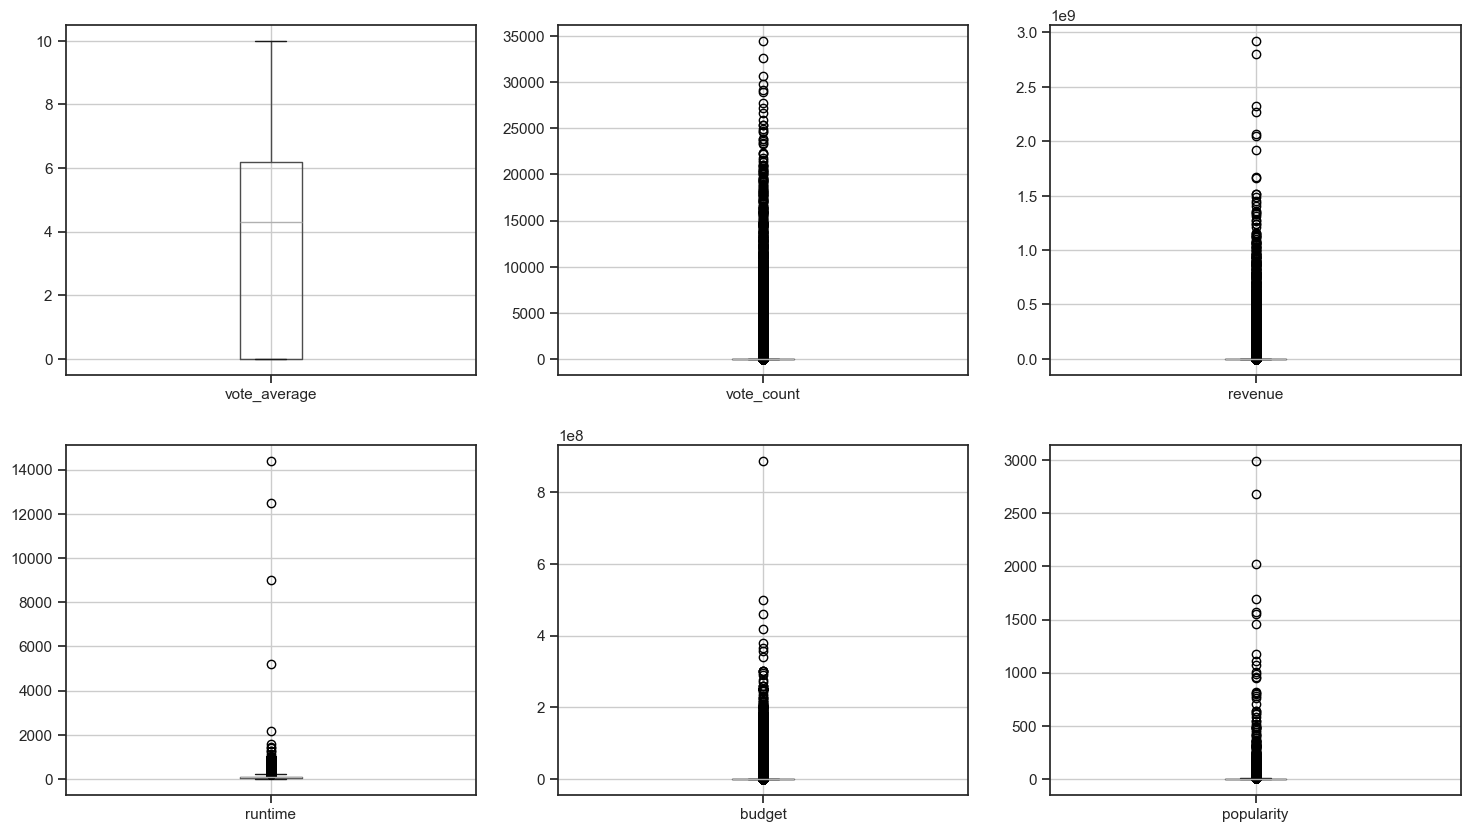

In [40]:
cleaned_movie_df_only_num = cleaned_movie_df.select_dtypes(include=["number"])

fig, axes = plt.subplots(nrows=2, ncols=int(len(cleaned_movie_df_only_num.columns)/2), figsize=(18, 10)) #Set subplots to show box plots

for ax, column in zip(axes.flat, cleaned_movie_df_only_num.columns): # Plot each features to each axes 
    cleaned_movie_df_only_num.boxplot(column=column, ax=ax)

plt.show()

Drawing the box plot raises suspicion as a significant number of values are clustered around 0. Therefore, I will remove values less than or equal to 0, and I will also remove the runtime values that are strangely distributed above 2000. Furthermore, since only released movies will likely have revenue anyway, I will remove the status feature as well.

In [41]:
cleaned_movie_df = cleaned_movie_df[(cleaned_movie_df["runtime"] < 2000) & (cleaned_movie_df["runtime"] > 0) 
                                     & (cleaned_movie_df["budget"] > 0) 
                                     & (cleaned_movie_df["revenue"] > 0) 
                                     & (cleaned_movie_df["popularity"] >= 0)
                                     & (cleaned_movie_df["status"] == "Released")
                                    ] # Remove outliers that values are below 0 and above 2000
cleaned_movie_df.drop(["status"], axis=1, inplace=True) # Remove status column as it is not needed anymore
cleaned_movie_df = cleaned_movie_df[~((cleaned_movie_df["vote_count"] < 0) & (cleaned_movie_df["vote_average"] != 0))] # vote average 가 0이 아닌데 vote count가 0이하인 경우 제거

In [42]:
cleaned_movie_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10424 entries, 27205 to 741451
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   title                 10424 non-null  object 
 1   vote_average          10424 non-null  float64
 2   vote_count            10424 non-null  int64  
 3   release_date          10424 non-null  object 
 4   revenue               10424 non-null  int64  
 5   runtime               10424 non-null  int64  
 6   adult                 10424 non-null  bool   
 7   budget                10424 non-null  int64  
 8   original_language     10424 non-null  object 
 9   overview              10424 non-null  object 
 10  popularity            10424 non-null  float64
 11  genres                10424 non-null  object 
 12  production_countries  10424 non-null  object 
 13  spoken_languages      10424 non-null  object 
dtypes: bool(1), float64(2), int64(4), object(7)
memory usage: 1.1+ MB


It's quite shocking. After removing the values less than or equal to 0, 250,000 values, which is about 96 percent of the total, disappeared, leaving only about 10,000 samples.

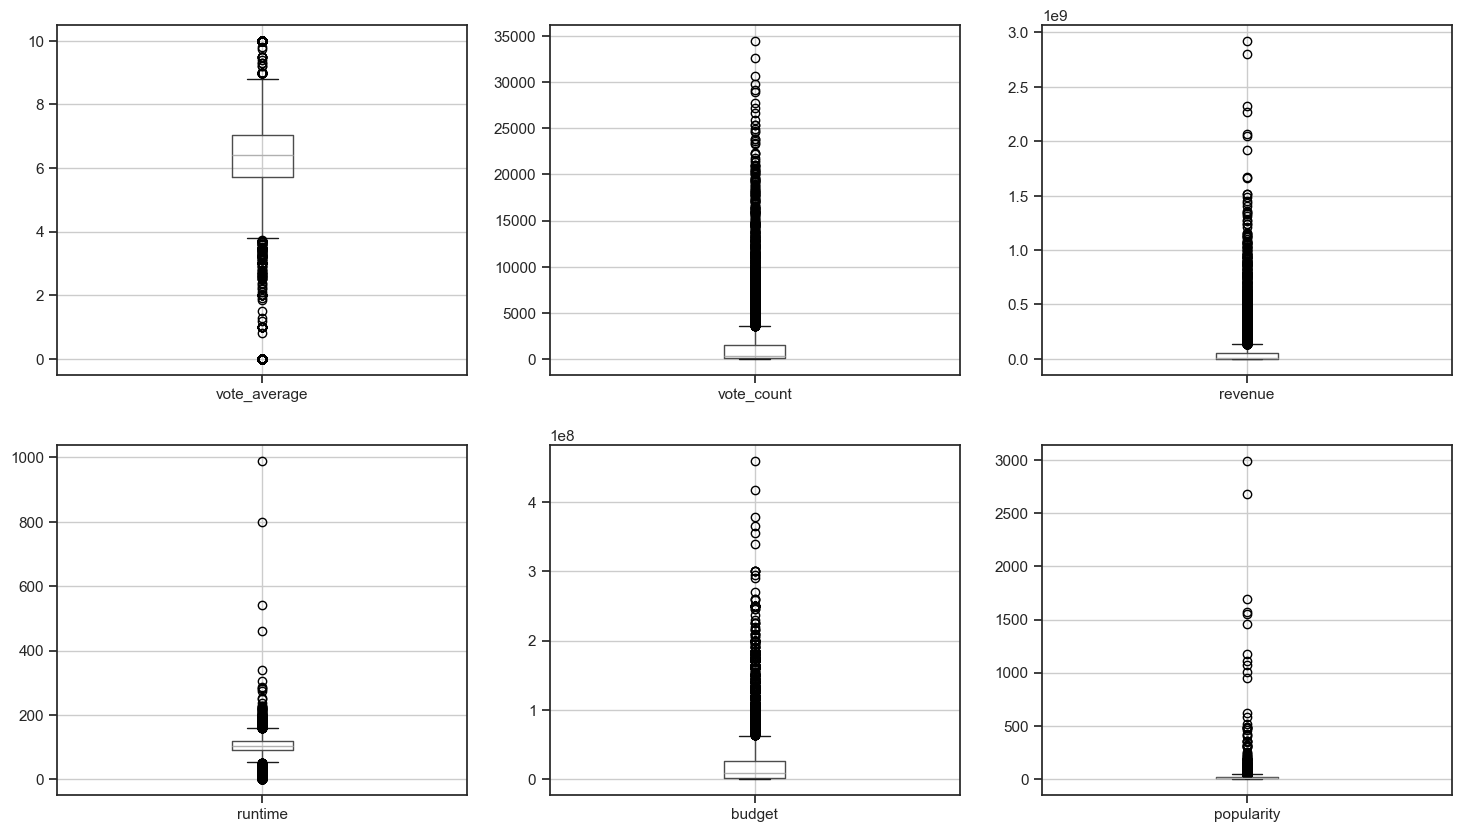

In [43]:
cleaned_movie_df_only_num = cleaned_movie_df.select_dtypes(include=["number"])

fig, axes = plt.subplots(nrows=2, ncols=int(len(cleaned_movie_df_only_num.columns)/2), figsize=(18, 10)) #Set subplots to show box plots

for ax, column in zip(axes.flat, cleaned_movie_df_only_num.columns): # Plot each features to each axes 
    cleaned_movie_df_only_num.boxplot(column=column, ax=ax)

plt.show()

In [44]:
cleaned_movie_df.describe()

,vote_average,vote_count,revenue,runtime,budget,popularity
count,10424.000000,10424.000000,1.042400e+04,10424.000000,1.042400e+04,10424.000000
mean,6.100579,1465.933039,6.414597e+07,104.094110,2.272010e+07,18.570874
std,1.828865,2933.067366,1.542129e+08,33.800605,3.752985e+07,60.477008
min,0.000000,0.000000,1.000000e+00,1.000000,1.000000e+00,0.000000
25%,5.713500,48.000000,1.327732e+06,92.000000,1.500000e+06,5.421000
50%,6.400000,355.000000,1.158890e+07,103.000000,8.741024e+06,12.646500
75%,7.024250,1463.500000,5.500000e+07,119.000000,2.600000e+07,20.080000
max,10.000000,34495.000000,2.923706e+09,990.000000,4.600000e+08,2994.357000


Although many values are still clustered at the bottom, since the gap between Hollywood movies, low-budget movies, popular movies, and unpopular movies is likely large, I will leave this as it is.

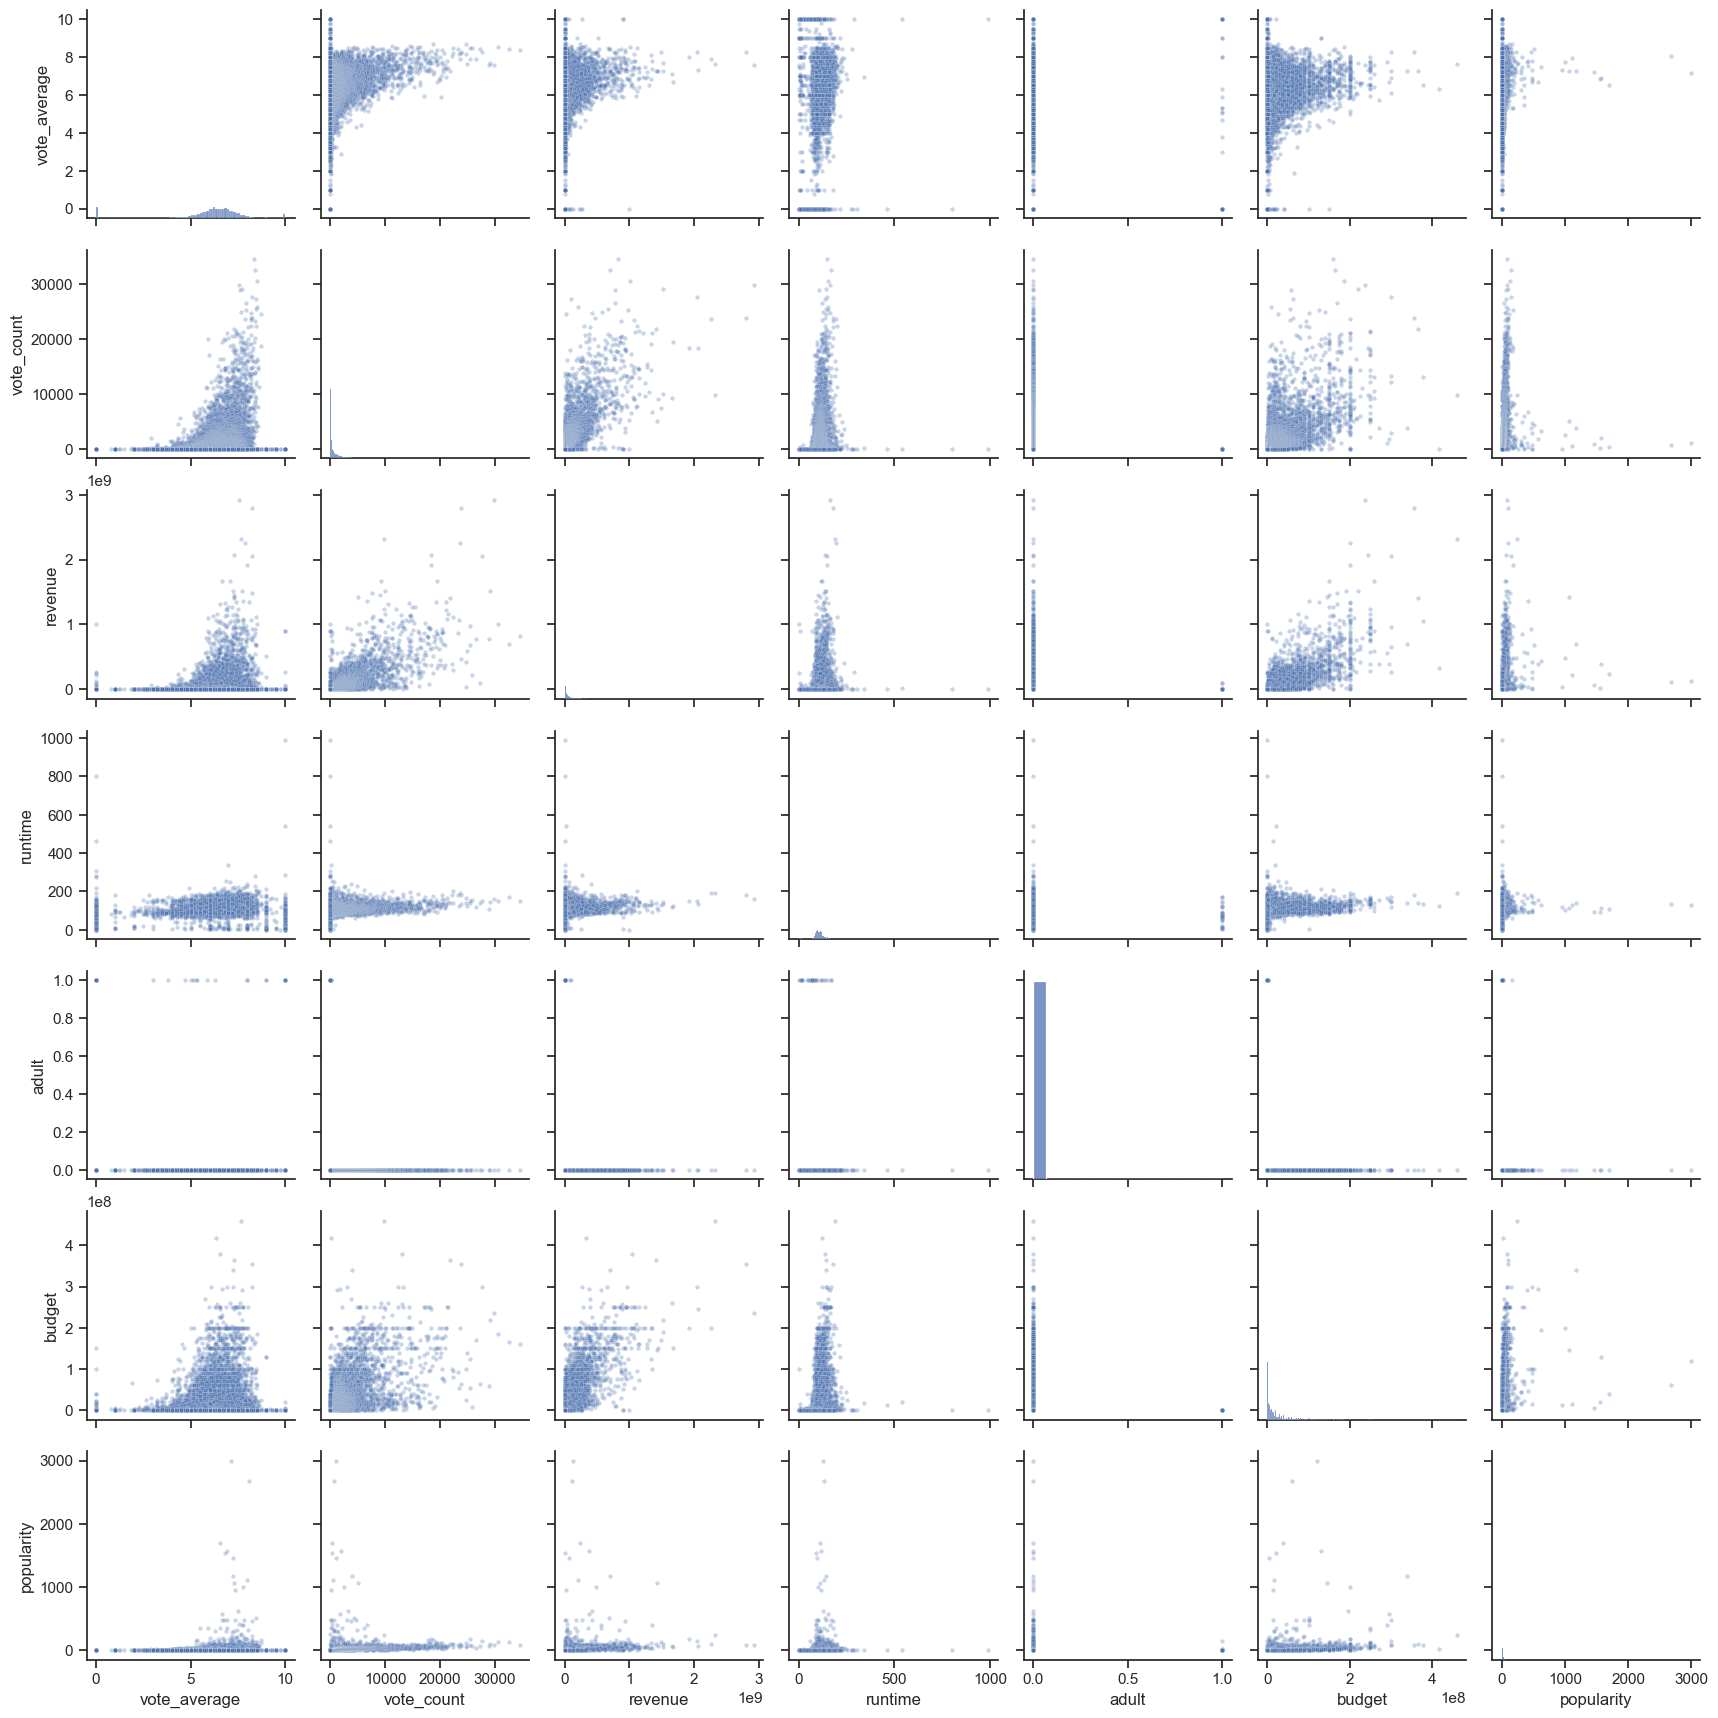

In [45]:
sns.set_theme(style="ticks")
sns.pairplot(data=cleaned_movie_df, plot_kws={"s":10, "alpha" : .3}) # Show all values colored by personal loan. discrete values also shows because may be we can find some patterns for personal loan
plt.show()

In [46]:
cleaned_movie_df_only_num_corr = cleaned_movie_df_only_num.corr()

cleaned_movie_df_only_num_corr

,vote_average,vote_count,revenue,runtime,budget,popularity
vote_average,1.000000,0.243516,0.162541,0.310116,0.136365,0.106065
vote_count,0.243516,1.000000,0.747841,0.189263,0.597793,0.195739
revenue,0.162541,0.747841,1.000000,0.175942,0.740104,0.232341
runtime,0.310116,0.189263,0.175942,1.000000,0.216045,0.081398
budget,0.136365,0.597793,0.740104,0.216045,1.000000,0.247209
popularity,0.106065,0.195739,0.232341,0.081398,0.247209,1.000000


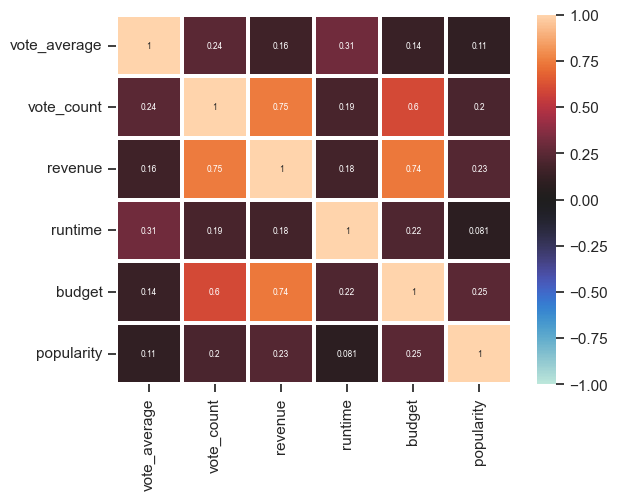

In [47]:
sns.heatmap(cleaned_movie_df_only_num_corr, linewidth=1.5, annot=True, vmin=-1., vmax=1., center = 0., annot_kws = {"size":6})
plt.show()

Looking at these plots, you can see that revenue, vote_count, and budget have a high correlation. This is somewhat understandable, as Hollywood movies tend to make a lot of money, and a higher vote_count implies a more popular movie. For now, I will train the model without dropping these features and then observe the results.

In [48]:
cleaned_movie_df.sample(10)

,title,vote_average,vote_count,release_date,revenue,runtime,adult,budget,original_language,overview,popularity,genres,production_countries,spoken_languages
id,,,,,,,,,,,,,,
10117,Action Jackson,5.498,207,1988-02-12,20256975,96,False,7000000,en,Vengeance drives a tough Detroit cop to stay o...,12.016,"Action, Comedy",United States of America,"English, French"
14073,Jodhaa Akbar,7.321,218,2008-02-13,28700000,213,False,5800000,hi,A sixteenth century love story about a marriag...,14.152,"Romance, History, Drama",India,"Hindi, Urdu"
10276,What About Bob?,6.840,733,1991-05-17,63710000,100,False,35000000,en,"Before going on vacation, self-involved psychi...",14.238,Comedy,United States of America,English
354556,Guardians,5.024,721,2017-02-14,4803565,100,False,5400000,ru,"During the Cold War, an organization called ""P...",15.591,"Action, Adventure, Comedy, Fantasy, Science Fi...",Russia,Russian
14170,Funny Farm,6.100,234,1988-06-03,25537221,101,False,19000000,en,Sportswriter Andy Farmer moves with his school...,8.871,Comedy,United States of America,English
10158,White Men Can't Jump,6.605,1195,1992-03-27,90753806,115,False,31000000,en,Two street basketball hustlers try to con each...,19.149,"Comedy, Drama",United States of America,English
697951,Lobão – Decadence Avec Elegance,0.000,0,2011-07-15,1000,15,False,7000,pt,"""Lobão - Não Há Estilo Sem Fracasso"" investiga...",0.600,Documentary,Brazil,Portuguese
454626,Sonic the Hedgehog,7.345,8901,2020-02-12,319715683,99,False,85000000,en,"Powered with incredible speed, Sonic The Hedge...",53.708,"Action, Science Fiction, Comedy, Family","Japan, United States of America",English
3080,Top Hat,7.301,269,1935-08-29,3202000,101,False,609000,en,Showman Jerry Travers is working for producer ...,12.266,"Comedy, Music, Romance",United States of America,"English, Italian"


## Encoding

For now, the plan is to use embeddings for title, overview, and production companies, use -1 and 1 values for adult, and for original language, genres, and spoken language, decompose the comma-separated values, assign numerical values to each, and input them using Multi-hot encoding. Since the embedding vector values will likely be between -1 and 1, the assigned numerical values should also be within this range. For the release_date value, after splitting it into year, month, day, and day of the week respectively, I will proceed by applying sine/cosine normalization and one-hot encoding.

### Multi-hot Encoding

In [49]:
encode_list = ["original_language", "genres", "production_countries"]

for feature in encode_list:
    test = cleaned_movie_df[feature].str.split(', ')
    list_lengths = test.apply(lambda x: len(x) if isinstance(x, list) else 0)
    print(test.explode().unique())

    print("Unique numbers:", len(test.explode().unique()))
    print("Max list length:", list_lengths.max())
    value_counts = test.explode().value_counts()
    minimum_count = 25
    print(f"values that appears more than {minimum_count} times in {feature}:", len(value_counts[value_counts>minimum_count]))
    print(value_counts[value_counts>minimum_count].index.tolist())
    print("---")

['en' 'ko' 'fr' 'ja' 'it' 'es' 'pt' 'hi' 'da' 'de' 'cn' 'id' 'zh' 'sv'
 'el' 'fa' 'th' 'ar' 'nb' 'pl' 'fi' 'tr' 'no' 'te' 'la' 'nl' 'hu' 'he'
 'ru' 'ro' 'gl' 'uk' 'tn' 'et' 'ta' 'ml' 'vi' 'cs' 'kn' 'ca' 'ku' 'tl'
 'iu' 'ms' 'hr' 'mr' 'sr' 'bn' 'bm' 'ur' 'pa' 'lt' 'si' 'xx' 'dz' 'km'
 'sk' 'gu' 'ne' 'lv' 'mn' 'sq' 'uz' 'dv' 'be' 'am' 'sw' 'az' 'lg' 'bs'
 'ht']
Unique numbers: 71
Max list length: 1
values that appears more than 25 times in original_language: 21
['en', 'hi', 'fr', 'es', 'ru', 'ja', 'ta', 'zh', 'it', 'fa', 'ml', 'ko', 'de', 'te', 'pt', 'tr', 'cn', 'ar', 'sv', 'bn', 'no']
---
['Action' 'Science Fiction' 'Adventure' 'Drama' 'Crime' 'Thriller'
 'Fantasy' 'Comedy' 'Romance' 'Western' 'Mystery' 'War' 'Animation'
 'Family' 'Horror' 'Music' 'History' 'Documentary' 'TV Movie']
Unique numbers: 19
Max list length: 10
values that appears more than 25 times in genres: 19
['Drama', 'Comedy', 'Action', 'Thriller', 'Romance', 'Adventure', 'Crime', 'Horror', 'Family', 'Science Fiction', '

The list of countries is quite long, but I will filter it down to just the major ones, apply multi-hot encoding, and then append it to the dataframe.

In [50]:
encoded_movie_df = cleaned_movie_df.drop(encode_list, axis=1)

minimum_thredhold = 25

for feature in encode_list:
    split_values = cleaned_movie_df[feature].str.split(', ')
    unique_counts = split_values.explode().value_counts()
    minimum_list = unique_counts[unique_counts < minimum_thredhold].index.tolist() ## 25개 미만인 것들 추출
    split_values = split_values.apply(lambda tags: ['other' if tag in minimum_list else tag for tag in tags]) ## 추출된 태그들은 other로 대체
    
    mlb = MultiLabelBinarizer()
    encoded_data = mlb.fit_transform(split_values) ## NaN은 이미 처리했으므로 바로 집어넣기

    multi_hot_encoded_df = pd.DataFrame(encoded_data, columns=mlb.classes_, index=split_values.index)
    multi_hot_encoded_df = multi_hot_encoded_df.replace(0, -1)
    multi_hot_encoded_df = multi_hot_encoded_df.add_prefix(feature + "_")
    encoded_movie_df = pd.concat([encoded_movie_df, multi_hot_encoded_df], axis=1)

    display(multi_hot_encoded_df.sample(10))

display(encoded_movie_df.head(10))
encoded_movie_df.info()

,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,original_language_es,original_language_fa,original_language_fr,original_language_hi,original_language_it,...,original_language_ml,original_language_no,original_language_other,original_language_pt,original_language_ru,original_language_sv,original_language_ta,original_language_te,original_language_tr,original_language_zh
id,,,,,,,,,,,,,,,,,,,,,
565927,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,-1,-1,-1,-1,-1,-1
10496,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
47502,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
15647,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
417466,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
177494,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
346,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
532671,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
70695,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1


,genres_Action,genres_Adventure,genres_Animation,genres_Comedy,genres_Crime,genres_Documentary,genres_Drama,genres_Family,genres_Fantasy,genres_History,genres_Horror,genres_Music,genres_Mystery,genres_Romance,genres_Science Fiction,genres_TV Movie,genres_Thriller,genres_War,genres_Western
id,,,,,,,,,,,,,,,,,,,
10529,1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1
5156,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
9426,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,1,-1,-1,-1,-1
37430,1,1,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
17813,-1,-1,-1,1,-1,-1,-1,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1
680936,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1
220669,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
309038,-1,-1,-1,1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
41402,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,1,-1,1,-1,-1,-1,-1,-1,-1


,production_countries_Argentina,production_countries_Australia,production_countries_Belgium,production_countries_Brazil,production_countries_Bulgaria,production_countries_Canada,production_countries_China,production_countries_Czech Republic,production_countries_Denmark,production_countries_Egypt,...,production_countries_South Africa,production_countries_South Korea,production_countries_Spain,production_countries_Sweden,production_countries_Switzerland,production_countries_Thailand,production_countries_Turkey,production_countries_United Kingdom,production_countries_United States of America,production_countries_other
id,,,,,,,,,,,,,,,,,,,,,
79694,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
14047,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
6844,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
14405,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
2001,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
1150895,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
1630,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
69,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
793685,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1


,title,vote_average,vote_count,release_date,revenue,runtime,adult,budget,overview,popularity,...,production_countries_South Africa,production_countries_South Korea,production_countries_Spain,production_countries_Sweden,production_countries_Switzerland,production_countries_Thailand,production_countries_Turkey,production_countries_United Kingdom,production_countries_United States of America,production_countries_other
id,,,,,,,,,,,,,,,,,,,,,
27205,Inception,8.364,34495,2010-07-15,825532764,148,False,160000000,"Cobb, a skilled thief who commits corporate es...",83.952,...,-1,-1,-1,-1,-1,-1,-1,1,1,-1
157336,Interstellar,8.417,32571,2014-11-05,701729206,169,False,165000000,The adventures of a group of explorers who mak...,140.241,...,-1,-1,-1,-1,-1,-1,-1,1,1,-1
155,The Dark Knight,8.512,30619,2008-07-16,1004558444,152,False,185000000,Batman raises the stakes in his war on crime. ...,130.643,...,-1,-1,-1,-1,-1,-1,-1,1,1,-1
19995,Avatar,7.573,29815,2009-12-15,2923706026,162,False,237000000,"In the 22nd century, a paraplegic Marine is di...",79.932,...,-1,-1,-1,-1,-1,-1,-1,1,1,-1
24428,The Avengers,7.710,29166,2012-04-25,1518815515,143,False,220000000,When an unexpected enemy emerges and threatens...,98.082,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
293660,Deadpool,7.606,28894,2016-02-09,783100000,108,False,58000000,The origin story of former Special Forces oper...,72.735,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
299536,Avengers: Infinity War,8.255,27713,2018-04-25,2052415039,149,False,300000000,As the Avengers and their allies have continue...,154.340,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
550,Fight Club,8.438,27238,1999-10-15,100853753,139,False,63000000,A ticking-time-bomb insomniac and a slippery s...,69.498,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1
118340,Guardians of the Galaxy,7.906,26638,2014-07-30,772776600,121,False,170000000,"Light years from Earth, 26 years after being a...",33.255,...,-1,-1,-1,-1,-1,-1,-1,-1,1,-1


<class 'pandas.core.frame.DataFrame'>
Index: 10424 entries, 27205 to 741451
Data columns (total 93 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   title                                          10424 non-null  object 
 1   vote_average                                   10424 non-null  float64
 2   vote_count                                     10424 non-null  int64  
 3   release_date                                   10424 non-null  object 
 4   revenue                                        10424 non-null  int64  
 5   runtime                                        10424 non-null  int64  
 6   adult                                          10424 non-null  bool   
 7   budget                                         10424 non-null  int64  
 8   overview                                       10424 non-null  object 
 9   popularity                                     104

Also, I will map the Boolean adult value to [-1, 1].

In [51]:
encoded_movie_df['is_adult'] = encoded_movie_df['adult'].map({True: 1, False: -1})
encoded_movie_df.drop(['adult'], axis=1, inplace=True)

display(encoded_movie_df.sample(10))
encoded_movie_df.info()

,title,vote_average,vote_count,release_date,revenue,runtime,budget,overview,popularity,spoken_languages,...,production_countries_South Korea,production_countries_Spain,production_countries_Sweden,production_countries_Switzerland,production_countries_Thailand,production_countries_Turkey,production_countries_United Kingdom,production_countries_United States of America,production_countries_other,is_adult
id,,,,,,,,,,,,,,,,,,,,,
300983,Yennai Arindhaal,6.900,46,2015-02-06,16000000,176,7900000,"Sathyadev, who is on a career break, is forced...",4.723,Tamil,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
1588,Bring It On,6.225,1556,2000-08-25,90449929,98,28000000,The Toro cheerleading squad from Rancho Carne ...,16.369,English,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
10439,Hocus Pocus,7.055,2719,1993-07-16,45395069,96,28000000,"After 300 years of slumber, three sister witch...",35.894,"English, French",...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
15035,Fire and Ice,6.652,237,1983-03-25,760883,81,1200000,"In this animated tale, a tiny village is destr...",16.925,English,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
11017,Billy Madison,6.185,1491,1995-02-10,26488734,90,10000000,Billy Madison is the 27 year-old son of Bryan ...,21.610,"French, Spanish, English",...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
297,Meet Joe Black,7.302,4609,1998-11-12,142940100,178,90000000,When the grim reaper comes to collect the soul...,43.274,"Dutch, English",...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
562,Die Hard,7.775,10202,1988-07-15,140767956,131,28000000,NYPD cop John McClane's plan to reconcile with...,36.754,"English, German, Italian",...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
373571,Godzilla: King of the Monsters,6.674,5479,2019-05-29,386600138,132,170000000,Follows the heroic efforts of the crypto-zoolo...,53.983,"Mandarin, English, Japanese",...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
449924,Ip Man 4: The Finale,7.257,1766,2019-12-19,176345966,107,52000000,"Following the death of his wife, Ip Man travel...",11.457,"English, Cantonese, Mandarin",...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1


<class 'pandas.core.frame.DataFrame'>
Index: 10424 entries, 27205 to 741451
Data columns (total 93 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   title                                          10424 non-null  object 
 1   vote_average                                   10424 non-null  float64
 2   vote_count                                     10424 non-null  int64  
 3   release_date                                   10424 non-null  object 
 4   revenue                                        10424 non-null  int64  
 5   runtime                                        10424 non-null  int64  
 6   budget                                         10424 non-null  int64  
 7   overview                                       10424 non-null  object 
 8   popularity                                     10424 non-null  float64
 9   spoken_languages                               104

First, since the number of samples has decreased too much, it seems likely that applying embeddings as well could lead to the curse of dimensionality. Therefore, for now, I will try extracting only the numerical data from this dataset and train the model with it.

# Split data sets

In [52]:
encoded_movie_df_numeric = encoded_movie_df.select_dtypes(include=np.number)
random_state = 42

X = encoded_movie_df_numeric.drop('revenue', axis=1)
y = encoded_movie_df_numeric['revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)

display(X_train.sample(10))

,vote_average,vote_count,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,...,production_countries_South Korea,production_countries_Spain,production_countries_Sweden,production_countries_Switzerland,production_countries_Thailand,production_countries_Turkey,production_countries_United Kingdom,production_countries_United States of America,production_countries_other,is_adult
id,,,,,,,,,,,,,,,,,,,,,
8328,6.684,2160,98,23000000,24.053,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
111190,6.111,902,100,16000000,18.537,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
477510,6.711,254,112,10000000,14.837,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
30596,6.800,338,139,23000000,15.563,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
11858,6.112,268,128,40000000,8.755,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
2023,6.811,1077,136,100000000,14.360,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,-1,1,1,-1
14574,7.849,6542,94,12500000,45.822,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,1,1,-1,-1
213444,7.571,7,118,743416,0.600,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
910854,0.000,0,1,1015,0.600,-1,-1,-1,-1,1,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1


Before proceeding with the training, for the convenience of training, I will adjust the remaining values, excluding the encoded ones, using a standard scaler.

In [53]:
X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train.iloc[:, 0:5])
X_test_scaled = X_scaler.transform(X_test.iloc[:, 0:5])

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.iloc[:, 0:5].columns, index=X_train.iloc[:, 0:5].index)
X_train_scaled = pd.concat([X_train_scaled, X_train.iloc[:, 5:]], axis=1)

X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_train.iloc[:, 0:5].columns, index=X_test.iloc[:, 0:5].index)
X_test_scaled = pd.concat([X_test_scaled, X_test.iloc[:, 5:]], axis=1)

display(X_test_scaled.describe())

,vote_average,vote_count,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,...,production_countries_South Korea,production_countries_Spain,production_countries_Sweden,production_countries_Switzerland,production_countries_Thailand,production_countries_Turkey,production_countries_United Kingdom,production_countries_United States of America,production_countries_other,is_adult
count,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,...,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000
mean,0.015262,0.022364,0.010694,-0.032215,-0.015521,-0.992326,-0.993285,-0.991367,-0.983693,0.527098,...,-0.981775,-0.942446,-0.983693,-0.987530,-0.991367,-0.990408,-0.765947,0.373621,-0.916547,-0.992326
std,0.986508,1.062560,0.925255,0.911408,0.655677,0.123678,0.115718,0.131148,0.179899,0.850008,...,0.190095,0.334438,0.179899,0.157469,0.131148,0.138209,0.643058,0.927804,0.400023,0.123678
min,-3.323779,-0.501748,-3.003757,-0.601546,-0.292154,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,-0.215395,-0.485518,-0.350487,-0.562256,-0.208556,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
50%,0.166336,-0.374669,-0.029762,-0.392004,-0.097658,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,-1.000000,-1.000000
75%,0.516438,0.003460,0.465904,0.079466,0.021303,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,-1.000000,-1.000000
max,2.129526,11.410185,6.851247,8.958809,18.000482,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [54]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

y_train_scaled = pd.DataFrame(y_train_scaled, index=y_train.index, columns=["revenue"])
y_test_scaled = pd.DataFrame(y_test_scaled, index=y_test.index, columns=["revenue"])


display(y_test_scaled.describe())

,revenue
count,2085.000000
mean,0.002421
std,1.027638
min,-0.417797
25%,-0.409286
50%,-0.341243
75%,-0.034316
max,18.647022


# Train Neural networks

In [ ]:
mlp_regressor = MLPRegressor(
    hidden_layer_sizes=(100, 100, 100),  
    activation='relu',
    solver='adam',
    alpha=0.001, 
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10, 
    learning_rate_init = 0.000001,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=True
)

mlp_regressor.fit(X_train_scaled, y_train_scaled.values.ravel())
y_pred = mlp_regressor.predict(X_test_scaled)

Iteration 1, loss = 1.48381622
Validation score: -2.830790
Iteration 2, loss = 1.44538426
Validation score: -2.718388
Iteration 3, loss = 1.40813020
Validation score: -2.609749
Iteration 4, loss = 1.37215597
Validation score: -2.504801
Iteration 5, loss = 1.33744219
Validation score: -2.402986
Iteration 6, loss = 1.30373876
Validation score: -2.305447
Iteration 7, loss = 1.27140782
Validation score: -2.210224
Iteration 8, loss = 1.24004487
Validation score: -2.118804
Iteration 9, loss = 1.20985394
Validation score: -2.030497
Iteration 10, loss = 1.18072568
Validation score: -1.945274
Iteration 11, loss = 1.15262121
Validation score: -1.862989
Iteration 12, loss = 1.12550323
Validation score: -1.783351
Iteration 13, loss = 1.09931350
Validation score: -1.706610
Iteration 14, loss = 1.07416871
Validation score: -1.632513
Iteration 15, loss = 1.04988592
Validation score: -1.561448
Iteration 16, loss = 1.02651237
Validation score: -1.493172
Iteration 17, loss = 1.00403433
Validation score:

In [56]:
mse = mean_squared_error(y_test_scaled.values.ravel(), y_pred)
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test_scaled.values.ravel(), y_pred)
r2 = r2_score(y_test_scaled.values.ravel(), y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.3651
Root Mean Squared Error (RMSE): 0.6042
Mean Absolute Error (MAE): 0.2770
R-squared (R2): 0.6541


Checking the R^2 value, it shows a quite decent accuracy of approximately 0.6541, even though the parameters were arbitrarily set. Among the features, budget and vote_count have correlations (i.e., r-values) of 0.74 and 0.75 respectively with revenue. If simple linear regression is performed for each feature, the resulting R^2 values are 0.5476 and 0.5625, respectively. Since the neural network achieves a higher result (0.6541) than predicting with each of these two features individually, it can be concluded that using a neural network for prediction proved effective.

In [57]:
# n_layers_range = range(1, 21)
# neurons_per_layer_range = range(10, 211, 10)

# results_neuron_layer = []


# print("\nStart to train MLPRegressor...")
# total_combinations = len(n_layers_range) * len(neurons_per_layer_range)
# count = 0

# for n_layers in n_layers_range:
#     for neurons in neurons_per_layer_range:
#         count += 1
#         print(f"Progression: {count}/{total_combinations} - layer: {n_layers}, neurons: {neurons}")


#         # example: n_layers=3, neurons=50 -> (50, 50, 50)
#         hidden_layer_config = tuple([neurons] * n_layers)


#         mlp_regressor = MLPRegressor(
#             hidden_layer_sizes=hidden_layer_config, 
#             activation='relu',
#             solver='adam',
#             alpha=0.001,
#             max_iter=5000,
#             early_stopping=True,
#             validation_fraction=0.1,
#             n_iter_no_change=10,
#             learning_rate_init = 0.000001,
#             learning_rate = 'adaptive',
#             random_state=random_state,
#             verbose=False
#         )

#         scores = cross_val_score(mlp_regressor, X_train_scaled, y_train_scaled.values.ravel() cv=5, scoring='r2')
#         print("Score of each folds:", scores)
#         print("Mean score:", np.mean(scores))


#         results_neuron_layer.append({'n_layers': n_layers, 'neurons': neurons, 'r2_score': np.mean(scores)})



After an epic run of 1286 minutes and 10.8 seconds, I finally obtained the results. I will save the results to avoid the disaster of having to run the code again later.

In [58]:
# results_df = pd.DataFrame(results_neuron_layer, columns=['n_layers', 'neurons', 'r2_score'])
# results_df.to_csv('./result/mlp_regressor_results.csv', index=False)

From now on, I will load the CSV file as a df to work with.

In [59]:
results_df = pd.read_csv('./result/mlp_regressor_results.csv')
results_df.head(10)

,n_layers,neurons,r2_score
0,1,10,0.463029
1,1,20,0.557723
2,1,30,0.575113
3,1,40,0.624571
4,1,50,0.634753
5,1,60,0.644975
6,1,70,0.631157
7,1,80,0.653885
8,1,90,0.630732
9,1,100,0.645945


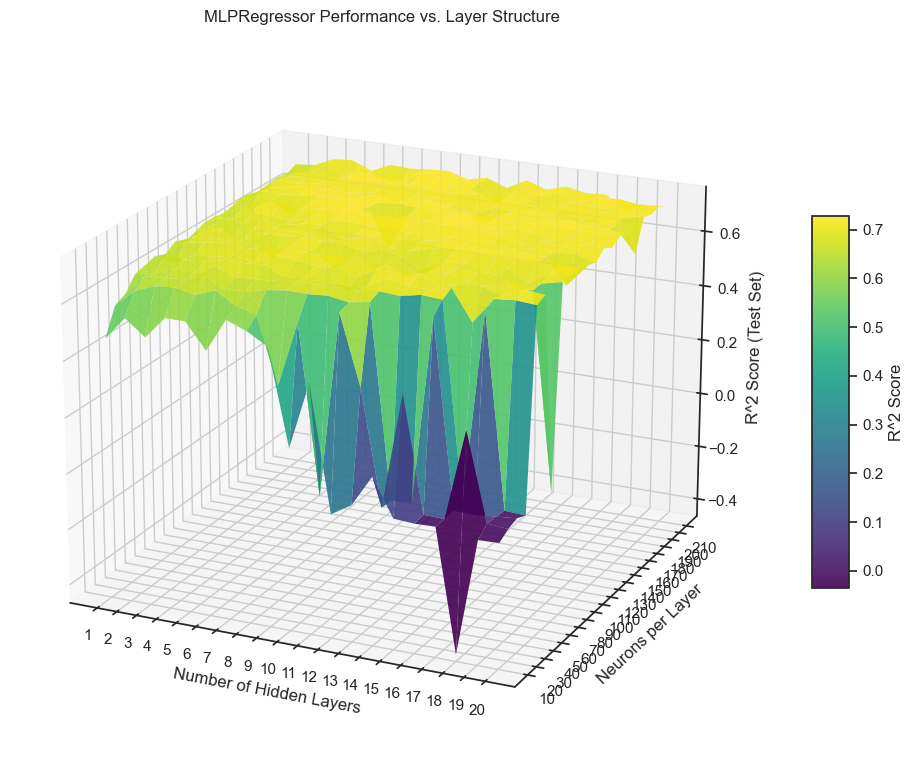

In [60]:
# Draw 3D surface plot

# Make grid for 3D plot
X_layers = np.array(results_df['n_layers'])
Y_neurons = np.array(results_df['neurons'])
Z_r2 = np.array(results_df['r2_score'])

unique_layers = np.unique(X_layers)
unique_neurons = np.unique(Y_neurons)

X_grid, Y_grid = np.meshgrid(unique_layers, unique_neurons)

Z_grid = Z_r2.reshape(len(unique_layers), len(unique_neurons)).T 

# Create 3D plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')


surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis',
                        linewidth=0, antialiased=True, alpha=0.9)


ax.set_xlabel('Number of Hidden Layers')
ax.set_ylabel('Neurons per Layer')
ax.set_zlabel('R^2 Score (Test Set)')
ax.set_title('MLPRegressor Performance vs. Layer Structure')


fig.colorbar(surf, shrink=0.5, aspect=10, label='R^2 Score')

ax.set_xticks(unique_layers)
ax.set_yticks(unique_neurons)

ax.view_init(elev=20, azim=-65)

plt.tight_layout()
plt.show()

t can be confirmed that the R2 score eventually stops around 0.7. Looking at this graph, it can be confirmed that as the number of Hidden Layers increases, more neurons per layer are also needed. There was a peculiar point I could observe because I limited the maximum number of training epochs to 2000: models with a low number of neurons per layer - 10 or 20 - always indicated that 2000 epochs were insufficient during training, regardless of the number of layers. While that could be an issue, considering the overall trend that the learning rate tends to increase as the number of neurons per layer increases, it is judged not to be a major problem.

Because of the values in the 'holes', the changes in the values at the 'peaks' are not clearly perceived. Therefore, to see the values at the peaks, I will filter to include only configurations where the number of hidden layers is 3 or more and the number of neurons per layer is 50 or more, and then check.

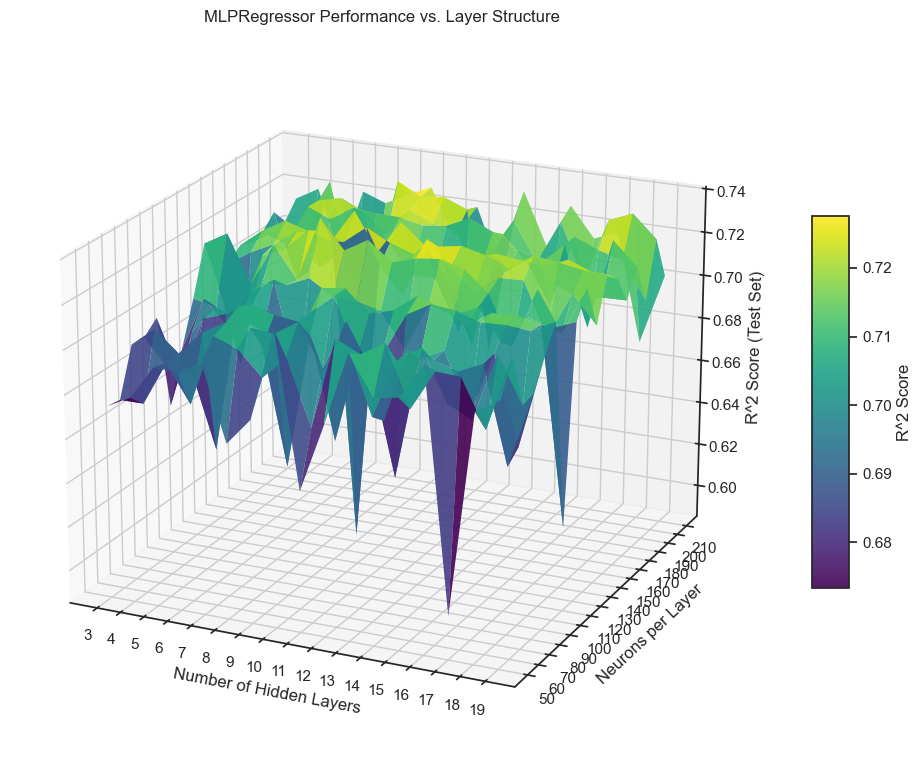

In [61]:
#Drawing the 3D plot with filtered data

results_df_filtered = results_df[(results_df['n_layers'] > 2) &(results_df['n_layers'] < 20) &  (results_df['neurons'] > 40)]

X_layers = np.array(results_df_filtered['n_layers'])
Y_neurons = np.array(results_df_filtered['neurons'])
Z_r2 = np.array(results_df_filtered['r2_score'])


unique_layers = np.unique(X_layers)
unique_neurons = np.unique(Y_neurons)

X_grid, Y_grid = np.meshgrid(unique_layers, unique_neurons)

Z_grid = Z_r2.reshape(len(unique_layers), len(unique_neurons)).T

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')


surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis',
                        linewidth=0, antialiased=True, alpha=0.9)


ax.set_xlabel('Number of Hidden Layers')
ax.set_ylabel('Neurons per Layer')
ax.set_zlabel('R^2 Score (Test Set)')
ax.set_title('MLPRegressor Performance vs. Layer Structure')


fig.colorbar(surf, shrink=0.5, aspect=10, label='R^2 Score')

ax.set_xticks(unique_layers)
ax.set_yticks(unique_neurons)


ax.view_init(elev=20, azim=-65)

plt.tight_layout() 
plt.show()

Zooming in on the graph of the peaks, it appears that up to approximately 130 neurons per layer, there is a trend where accuracy increases while fluctuating sideways. After that point, it's possible to observe a continued sideways movement (plateauing) without significant performance improvement. And the most surprising point was that the number of hidden layers does not seem to show a clear impact on the overall performance; rather, it seems to show spots of good performance when the number of hidden layers is around 7 to 13.

Now, I will find the configuration that showed the best performance among those measured and finalize it as the layer structure to be used for future performance evaluations.

In [62]:
max_R2_row = results_df.nlargest(1, 'r2_score')
display(max_R2_row)
neurons = max_R2_row['neurons'].values[0]
n_layers = max_R2_row['n_layers'].values[0]

hidden_layer_config_final = tuple([neurons] * n_layers)
print(hidden_layer_config_final)

,n_layers,neurons,r2_score
159,8,130,0.737997


(130, 130, 130, 130, 130, 130, 130, 130)


Checking the results, it can be confirmed that the highest results are shown when the number of hidden layers is 8 and the number of neurons per hidden layer is 130.

In [63]:


mlp_regressor = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final,
    activation='relu',
    solver='adam',
    alpha=0.001,
    max_iter=2000,
    early_stopping=True, 
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = 0.000001,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=False
)


mlp_regressor.fit(X_train_scaled, y_train_scaled.values.ravel())


y_pred = mlp_regressor.predict(X_test_scaled)


r2 = r2_score(y_test_scaled.values.ravel(), y_pred)

print(f"R^2 Score: {r2:.4f}")

R^2 Score: 0.7380


It is possible to confirm that the R^2 value has increased by approximately 0.06 compared to the value I had set.

Now, based on the confirmed neuron dimensions, I will adjust other hyperparameters and check the resulting values. First, I will try changing the activation function.

In [64]:
# ________emergency break point

First, I will conduct an experiment by varying the learning rate, which adjusts the values in gradient descent.

In [65]:
# learning_rate_values = np.logspace(-6, -2, num=5)
# count = 0
# results = []

# for learning_rate in learning_rate_values:
#     count += 1
#     print(f"Progression: {count}/{len(learning_rate_values)} - learning rate: {learning_rate}")


#     mlp_regressor = MLPRegressor(
#         hidden_layer_sizes=hidden_layer_config_final,  
#         activation='relu',
#         solver='adam',
#         alpha=0.001,
#         max_iter=2000, 
#         early_stopping=True, 
#         validation_fraction=0.1, 
#         n_iter_no_change=10,
#         learning_rate_init = learning_rate,
#         learning_rate = 'adaptive',
#         random_state=random_state,
#         verbose=False
#     )
    

#     scores = cross_val_score(mlp_regressor, X_train_scaled, y_train_scaled.values.ravel(), cv=5, scoring='r2')
#     print("Score of each folds:", scores)
#     print("Mean score:", np.mean(scores))


#     results.append({'learning rate': learning_rate, 'r2_score': np.mean(scores)})

# print(results)

It can be confirmed that 1e-05 recorded a higher R2 score than the 1e-06 value we used in the experiment. Therefore, I will set the learning rate to 1e-05.

In [66]:
learning_rate_final = 1e-5

In [67]:
# results = []
# count = 0

# for activation in ['relu', 'tanh', 'logistic', 'identity']:
#     count += 1
#     print(f"Progression: {count}/4 - activation: {activation}")

#    
#     mlp_regressor = MLPRegressor(
#         hidden_layer_sizes=hidden_layer_config_final, 
#         activation=activation,
#         solver='adam',
#         alpha=0.001,
#         max_iter=2000,
#         early_stopping=True,
#         validation_fraction=0.1,
#         n_iter_no_change=10,
#         learning_rate_init = learning_rate_final,
#         learning_rate = 'adaptive',
#         random_state=random_state,
#         verbose=False
#     )
    

#     scores = cross_val_score(mlp_regressor, X_train_scaled, y_train_scaled.values.ravel(), cv=5, scoring='r2')
#     print("Score of each folds:", scores)
#     print("Mean score:", np.mean(scores))


#     results.append({'activation': activation, 'r2_score': np.mean(scores)})

# print(results)

The relu function, which we have been using from the beginning, shows the highest results, and tanh seems to follow it. Analyzing these results, the relu function tends to learn faster than other functions in gradient descent-based optimization, and this point seems to be reflected here, while logistic is suspected of suffering from vanishing gradients. Identity showed the second-highest score after relu, but due to this function's characteristic of reflecting the x value directly, the advantage of having 8 hidden layers seems unlikely to be significant.

In [68]:
activation_final = 'relu'

In [69]:
# results = []
# count = 0

# for solver in ['sgd', 'adam', 'lbfgs']:
#     count += 1
#     print(f"Progression: {count}/3 - solver: {solver}")


#     mlp_regressor = MLPRegressor(
#         hidden_layer_sizes=hidden_layer_config_final,
#         activation=activation_final,
#         solver= solver,
#         alpha=0.001,
#         max_iter=10000,
#         early_stopping=True,
#         validation_fraction=0.1,
#         n_iter_no_change=10,
#         learning_rate_init = learning_rate_final,
#         learning_rate = 'adaptive',
#         random_state=random_state,
#         verbose=False
#     )
    

#     scores = cross_val_score(mlp_regressor, X_train_scaled, y_train_scaled.values.ravel(), cv=5, scoring='r2')
#     print("Score of each folds:", scores)
#     print("Mean score:", np.mean(scores))


#     results.append({'solver': solver, 'r2_score': np.mean(scores)})

# print(results)

It can be seen that the Adaptive Moment Estimation (Adam) method is more effective than the Stochastic Gradient Descent (SGD) method. Since Adam is generally considered an improvement over SGD, this result seems reasonable. In the case of lbfgs, it hit the iteration limit even when max_iter was originally set to 2000. When I increased it to 10000, the accuracy actually dropped further, resulting in a state where it couldn't learn properly.

In [70]:
solver_final = 'adam'

This time, I will examine by adjusting the alpha value, which signifies regularization.

In [71]:
# alpha_values = np.logspace(-6, -2, num=5)
# results = []
# count = 0

# for alpha in alpha_values:
#     count += 1
#     print(f"Progression: {count}/{len(alpha_values)} - alpha: {alpha}")


#     mlp_regressor = MLPRegressor(
#         hidden_layer_sizes=hidden_layer_config_final,
#         activation=activation_final,
#         solver= solver_final,
#         alpha=alpha,
#         max_iter=10000,
#         early_stopping=True,
#         validation_fraction=0.1,
#         n_iter_no_change=10,
#         learning_rate_init = learning_rate_final,
#         learning_rate = 'adaptive',
#         random_state=random_state,
#         verbose=False
#     )
    

#     scores = cross_val_score(mlp_regressor, X_train_scaled, y_train_scaled.values.ravel(), cv=5, scoring='r2')
#     print("Score of each folds:", scores)
#     print("Mean score:", np.mean(scores))


#     results.append({'alpha': alpha, 'r2_score': np.mean(scores)})
#     results.append({'alpha': alpha, 'r2_score': np.mean(scores)})

# print(results)

Overall, there isn't a significant difference, with R^2 scores staying between 0.748 and 0.749. Still, believing it's better to maximize regularization, I will choose 0.001, which yields the highest R^2 score among the relatively larger alpha values.

In [72]:
alpha_final = 0.001

Now, I will build the model with the finalized values, train it, and then proceed with the evaluation.

In [73]:
movie_revenue_mlp_regressor = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final,  # 8 * 130 Hidden Layers
    activation=activation_final,
    solver= solver_final,
    alpha=alpha_final,
    max_iter=10000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=False
)

movie_revenue_mlp_regressor.fit(X_train_scaled, y_train_scaled.values.ravel())

y_pred = movie_revenue_mlp_regressor.predict(X_test_scaled)

## Model Evaluation

이제 생성한 모델을 이용하여 얼마나 정확하게 예측하였는지 평가해보도록 하겠다.

In [74]:
mse = mean_squared_error(y_test_scaled.values.ravel(), y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_scaled.values.ravel(), y_pred)
r2 = r2_score(y_test_scaled.values.ravel(), y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.2720
Root Mean Squared Error (RMSE): 0.5216
Mean Absolute Error (MAE): 0.2063
R-squared (R2): 0.7423


Now, I will evaluate how accurately it predicted using the generated model.

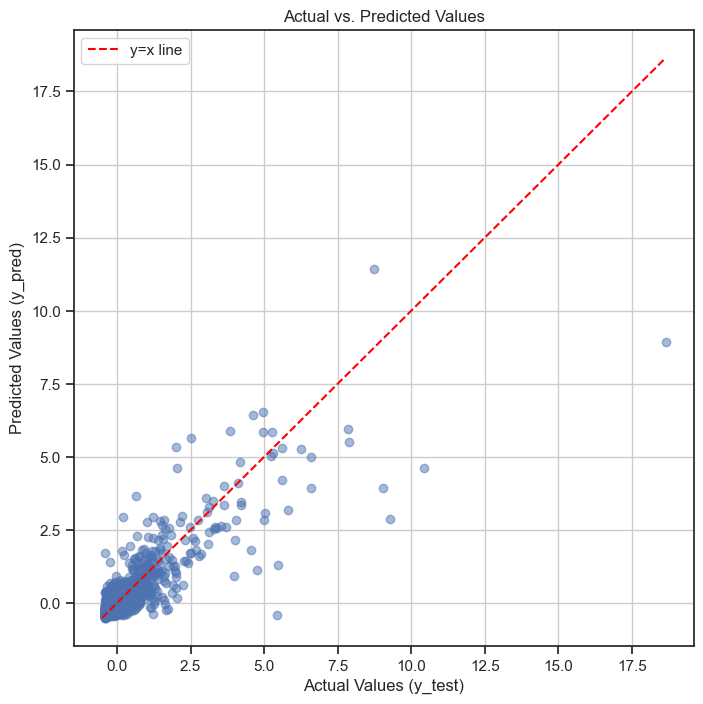

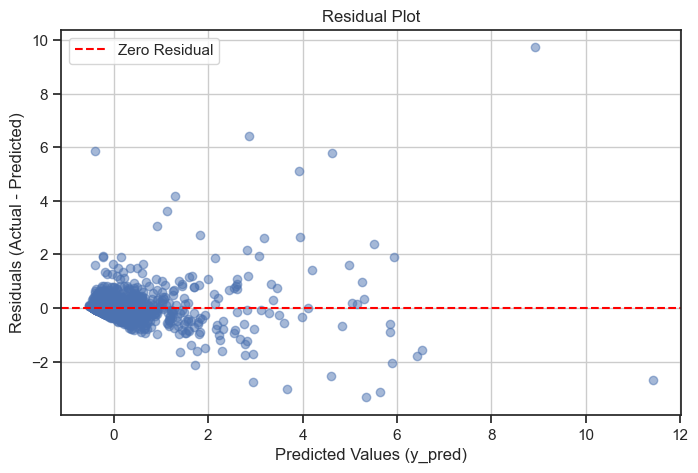

In [75]:

# --- Actual vs. Predicted ---
plt.figure(figsize=(8, 8))
plt.scatter(y_test_scaled, y_pred, alpha=0.5)
plt.plot([min(y_test_scaled.values.ravel().min(), y_pred.min()), max(y_test_scaled.values.ravel().max(), y_pred.max())],
         [min(y_test_scaled.values.ravel().min(), y_pred.min()), max(y_test_scaled.values.ravel().max(), y_pred.max())],
         color='red', linestyle='--', label='y=x line') # y=x
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

# --- Residual Plot (vs. Predicted Values) ---
residuals = y_test_scaled.values.ravel() - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual') # y=0
plt.xlabel("Predicted Values (y_pred)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.grid(True)
plt.show()

As might be expected, the result obtained was that as the values increase, the predicted values also become more spread out.

Looking at it this way, it seems difficult to make an accurate distinction because there are many extreme prediction values extending towards 17.5 from what appears to be a normal distribution. I will try looking at the results separately, focusing only on the instances where the actual values are 3 or less.

In [76]:
y_pred_df = pd.DataFrame(y_pred, index=y_test_scaled.index, columns=["revenue"])

y_test_scaled_test =  y_test_scaled[y_test_scaled["revenue"] < 3]
y_pred_test =  y_pred_df.loc[y_test_scaled_test.index]
# display(y_test_scaled_test[y_test_scaled_test.isna().any(axis=1)])
# display(y_pred_test[y_pred_test.isna().any(axis=1)])

mse = mean_squared_error(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())
r2 = r2_score(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.1088
Root Mean Squared Error (RMSE): 0.3298
Mean Absolute Error (MAE): 0.1680
R-squared (R2): 0.5899


Examining only the values less than or equal to 3 revealed a shocking result: the R^2 value dropped significantly.

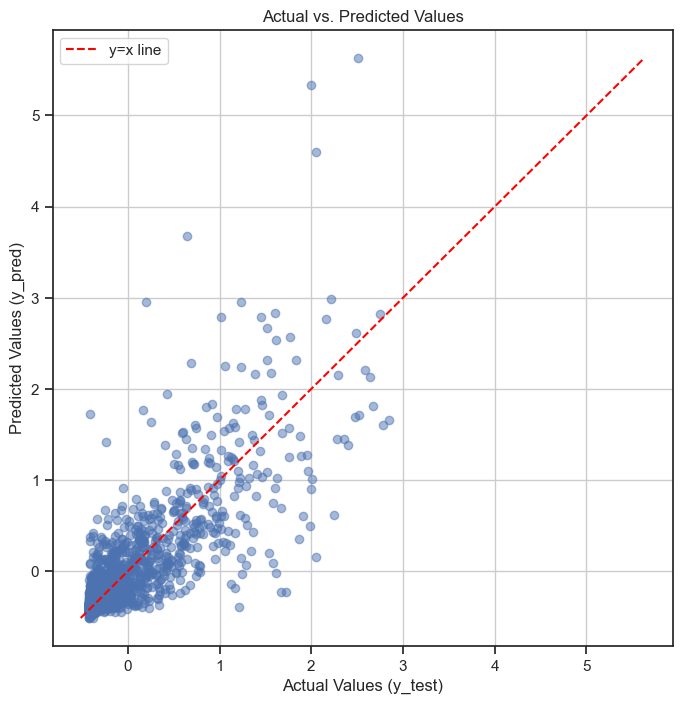

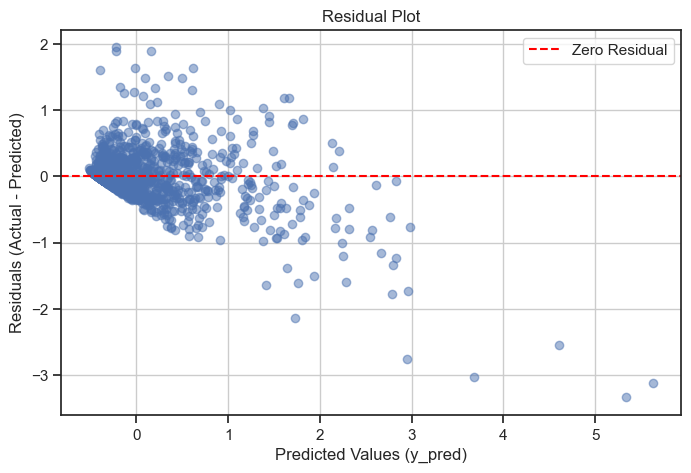

In [77]:

# --- 실제값 vs. 예측값 플롯 ---
plt.figure(figsize=(8, 8))
plt.scatter(y_test_scaled_test, y_pred_test, alpha=0.5)
plt.plot([min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         [min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         color='red', linestyle='--', label='y=x line') # y=x 직선
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

# --- 잔차 플롯 (vs. 예측값) ---
residuals = y_test_scaled_test.values.ravel() - y_pred_test.values.ravel()
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual') # 잔차 0 기준선
plt.xlabel("Predicted Values (y_pred)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.grid(True)
plt.show()

Looking at the graph, it seems there is a tendency to predict higher than the actual values. Perhaps the extreme values greater than 3 in the normal distribution are causing this result. I will try refining the data and retraining the model.

### Make another Neural Network model (pruned dataset)

In [78]:
y_train_scaled_pruned = y_train_scaled[y_train_scaled["revenue"] < 3]
X_train_scaled_pruned = X_train_scaled.loc[y_train_scaled_pruned.index]
y_test_scaled_pruned = y_test_scaled[y_test_scaled["revenue"] < 3]
X_test_scaled_pruned = X_test_scaled.loc[y_test_scaled_pruned.index]

movie_revenue_mlp_regressor_pruned = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final,  # 8 * 130 Hidden Layers
    activation=activation_final,
    solver= solver_final,
    alpha=alpha_final,
    max_iter=10000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=False
)

movie_revenue_mlp_regressor_pruned.fit(X_train_scaled_pruned, y_train_scaled_pruned.values.ravel())

y_pred = movie_revenue_mlp_regressor_pruned.predict(X_test_scaled)

In [79]:
y_pred_df = pd.DataFrame(y_pred, index=y_test_scaled.index, columns=["revenue"])

y_test_scaled_test =  y_test_scaled[y_test_scaled["revenue"] < 3]
y_pred_test =  y_pred_df.loc[y_test_scaled_test.index]

mse = mean_squared_error(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())
r2 = r2_score(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.0804
Root Mean Squared Error (RMSE): 0.2835
Mean Absolute Error (MAE): 0.1530
R-squared (R2): 0.6970


It can be confirmed that the R^2 score has increased to approximately 0.6970, which is close to 0.7.

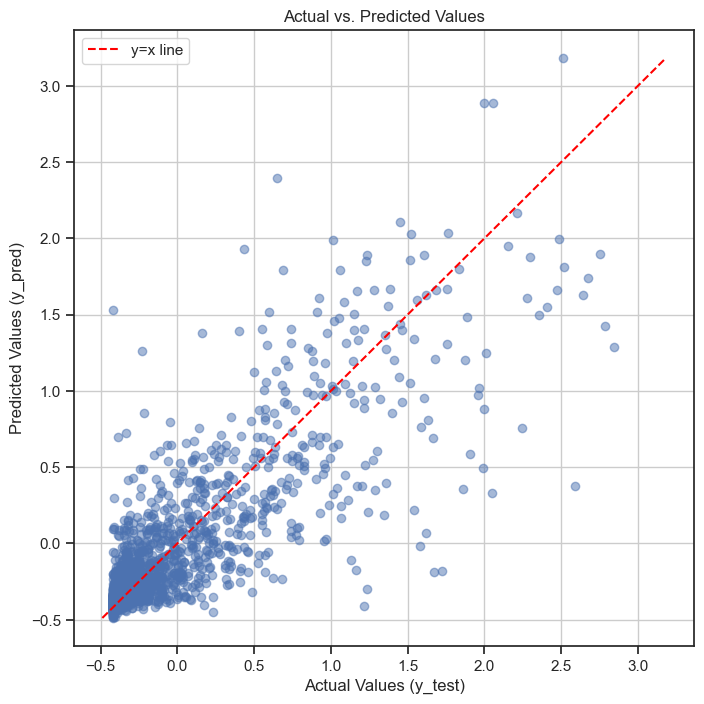

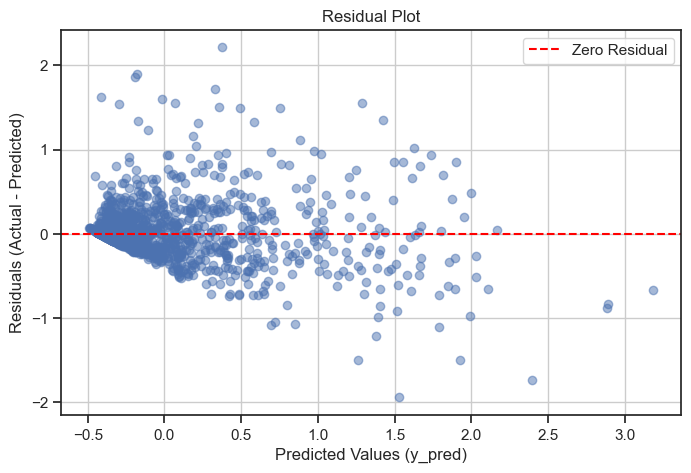

In [80]:
# --- Evaluate by plots ---

plt.figure(figsize=(8, 8))
plt.scatter(y_test_scaled_test, y_pred_test, alpha=0.5)
plt.plot([min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         [min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         color='red', linestyle='--', label='y=x line') 
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True)
plt.show()


residuals = y_test_scaled_test.values.ravel() - y_pred_test.values.ravel()
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual') 
plt.xlabel("Predicted Values (y_pred)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.grid(True)
plt.show()

This time, it seems like there's an overall tendency to predict higher when the actual value is low, and lower when the actual value is high.

## Make Neural Network with embedding

This time, I will try embedding the 'overview' using embeddings, then train the model including this, to see if there is any performance improvement.

In [81]:
encoded_movie_df

,title,vote_average,vote_count,release_date,revenue,runtime,budget,overview,popularity,spoken_languages,...,production_countries_South Korea,production_countries_Spain,production_countries_Sweden,production_countries_Switzerland,production_countries_Thailand,production_countries_Turkey,production_countries_United Kingdom,production_countries_United States of America,production_countries_other,is_adult
id,,,,,,,,,,,,,,,,,,,,,
27205,Inception,8.364,34495,2010-07-15,825532764,148,160000000,"Cobb, a skilled thief who commits corporate es...",83.952,"English, French, Japanese, Swahili",...,-1,-1,-1,-1,-1,-1,1,1,-1,-1
157336,Interstellar,8.417,32571,2014-11-05,701729206,169,165000000,The adventures of a group of explorers who mak...,140.241,English,...,-1,-1,-1,-1,-1,-1,1,1,-1,-1
155,The Dark Knight,8.512,30619,2008-07-16,1004558444,152,185000000,Batman raises the stakes in his war on crime. ...,130.643,"English, Mandarin",...,-1,-1,-1,-1,-1,-1,1,1,-1,-1
19995,Avatar,7.573,29815,2009-12-15,2923706026,162,237000000,"In the 22nd century, a paraplegic Marine is di...",79.932,"English, Spanish",...,-1,-1,-1,-1,-1,-1,1,1,-1,-1
24428,The Avengers,7.710,29166,2012-04-25,1518815515,143,220000000,When an unexpected enemy emerges and threatens...,98.082,"English, Hindi, Russian",...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
752196,Is This Water?,0.000,0,2020-08-26,2,11,1,"A Movie about Water, Thievery, and Being a Pri...",0.621,English,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1
738178,Me Within,0.000,0,2020-08-30,1,5,1,Some people are expendable. Some people are ca...,0.600,English,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
744252,4 Ways to Live a Healthy Life,0.000,0,2019-11-01,50,5,30,A simple how to on remaining healthy during th...,0.600,English,...,-1,-1,-1,-1,-1,-1,-1,1,-1,-1


In [82]:
# Load the pre-trained Sentence Transformer model
model_name = 'all-MiniLM-L6-v2'
try:
    model = SentenceTransformer(model_name)
    print(f"\nSentence Transformer model: '{model_name}' Loaded Successfully.")
    embedding_dimension = model.get_sentence_embedding_dimension()
    print(f"embedding dimention: {embedding_dimension}")
except Exception as e:
    print(e)

# Convert the 'overview' column to a list of vectors
target_column = 'overview'

texts_to_embed = encoded_movie_df[target_column].tolist()

embeddings = model.encode(texts_to_embed, show_progress_bar=True)
print(f"Shape of embedding vectors: {embeddings.shape}") 


Sentence Transformer model: 'all-MiniLM-L6-v2' Loaded Successfully.
embedding dimention: 384


Batches:   0%|          | 0/326 [00:00<?, ?it/s]

Shape of embedding vectors: (10424, 384)


It can be confirmed that the embedding has completed successfully. I will append these embedded vectors to the dataset.

In [83]:
embedding_col_names = [f'{target_column}_embed_{i}' for i in range(embedding_dimension)] # Create column names for the embeddings

embeddings_df = pd.DataFrame(embeddings, columns=embedding_col_names, index=encoded_movie_df.index)

embedded_movie_df = pd.concat([encoded_movie_df_numeric, embeddings_df], axis=1)

embedded_movie_df.sample(10)

,vote_average,vote_count,revenue,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,...,overview_embed_374,overview_embed_375,overview_embed_376,overview_embed_377,overview_embed_378,overview_embed_379,overview_embed_380,overview_embed_381,overview_embed_382,overview_embed_383
id,,,,,,,,,,,,,,,,,,,,,
6391,7.044,34,938881,82,1800000,2.905,-1,-1,-1,-1,...,0.016331,-0.047015,-0.063843,0.088733,-0.025464,0.102121,0.021282,-0.068199,-0.039713,-0.004756
7183,5.770,852,73090611,109,60795000,19.676,-1,-1,-1,-1,...,-0.003341,-0.018163,-0.003677,0.005333,0.000782,0.045724,-0.003058,0.040608,0.002006,-0.010633
424139,6.542,4342,259900000,106,10000000,30.021,-1,-1,-1,-1,...,-0.023141,-0.100192,0.034532,-0.023821,-0.047383,0.000170,-0.028007,-0.060409,0.039781,0.088933
4942,5.795,405,41299492,114,58000000,8.370,-1,-1,-1,-1,...,-0.000503,0.063079,-0.040367,0.054388,-0.056291,-0.049991,0.027889,0.039177,0.020306,0.027724
25943,5.714,91,6939946,95,25000000,5.540,-1,-1,-1,-1,...,0.021620,-0.080649,-0.053586,-0.008885,-0.063634,-0.005586,0.021599,-0.027935,0.025613,-0.020372
123103,5.108,300,58510,89,2000000,13.231,-1,-1,-1,-1,...,0.080454,-0.045426,0.011440,0.034993,0.015929,0.051559,0.045502,0.005841,-0.003432,-0.082147
550231,7.334,529,3215636,107,21000000,13.015,-1,-1,-1,-1,...,0.032742,-0.062764,-0.016076,0.021441,-0.067288,0.016270,0.045464,0.035320,-0.025949,-0.005392
8077,6.400,5066,159773545,114,50000000,28.981,-1,-1,-1,-1,...,0.016048,-0.029453,0.002438,0.071413,0.008019,-0.049514,-0.092177,0.043528,0.069210,-0.007986
16007,6.949,614,29667169,126,20000000,17.425,-1,-1,-1,-1,...,0.074087,-0.034110,0.028988,0.080281,-0.114675,-0.013505,0.132116,0.041861,0.068011,0.004252


And I will also add the date. The year will be normalized between -1 and 1, while the month and day will be represented using trigonometric functions to capture their cyclical nature.

In [84]:
target_column = 'release_date'

date_df = pd.DataFrame(pd.to_datetime(encoded_movie_df[target_column], errors='coerce'), columns=['release_date'])
display(date_df.sample(10))

date_df['year'] = date_df['release_date'].dt.year
date_df['month'] = date_df['release_date'].dt.month
date_df['day'] = date_df['release_date'].dt.day

display(date_df)

,release_date
id,
9647,1988-11-22
27995,1986-08-08
14359,2008-02-27
8491,1989-07-05
50321,2011-03-09
28485,1978-08-12
55985,2009-05-01
1308596,2024-06-23
10946,2007-10-10


,release_date,year,month,day
id,,,,
27205,2010-07-15,2010,7,15
157336,2014-11-05,2014,11,5
155,2008-07-16,2008,7,16
19995,2009-12-15,2009,12,15
24428,2012-04-25,2012,4,25
...,...,...,...,...
752196,2020-08-26,2020,8,26
738178,2020-08-30,2020,8,30
744252,2019-11-01,2019,11,1


In [85]:
scaler_year = MinMaxScaler(feature_range=(-1, 1))

date_df_scaled = pd.DataFrame()
date_df_scaled['year_scaled'] = pd.DataFrame(scaler_year.fit_transform(date_df["year"].values.reshape(-1, 1)), columns=["year_scaled"], index=date_df.index)


cycle_months = 12
date_df_scaled['month_sin'] = np.sin(2 * np.pi * date_df['month'] / cycle_months)
date_df_scaled['month_cos'] = np.cos(2 * np.pi * date_df['month'] / cycle_months)

cycle_days = 31


date_df_scaled['day_sin'] = np.sin(2 * np.pi * date_df['day'] / cycle_days)
date_df_scaled['day_cos'] = np.cos(2 * np.pi * date_df['day'] / cycle_days)

date_df_scaled.sample(10)

,year_scaled,month_sin,month_cos,day_sin,day_cos
id,,,,,
242582,0.819820,-8.660254e-01,5.000000e-01,-0.998717,-0.050649
88005,0.783784,1.224647e-16,-1.000000e+00,-0.968077,-0.250653
16911,0.711712,-2.449294e-16,1.000000e+00,-0.485302,-0.874347
47327,0.765766,8.660254e-01,5.000000e-01,-0.988468,0.151428
50646,0.765766,-5.000000e-01,-8.660254e-01,-0.394356,0.918958
336011,0.855856,-1.000000e+00,-1.836970e-16,0.394356,0.918958
11638,0.657658,1.000000e+00,6.123234e-17,-0.937752,0.347305
53049,0.423423,-1.000000e+00,-1.836970e-16,-0.485302,-0.874347
13435,0.603604,-2.449294e-16,1.000000e+00,-0.651372,-0.758758


Now that it's confirmed to be applied correctly, I will add it to the dataframe.

In [86]:
embedded_movie_df = pd.concat([embedded_movie_df, date_df_scaled], axis=1)

embedded_movie_df.sample(10)

,vote_average,vote_count,revenue,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,...,overview_embed_379,overview_embed_380,overview_embed_381,overview_embed_382,overview_embed_383,year_scaled,month_sin,month_cos,day_sin,day_cos
id,,,,,,,,,,,,,,,,,,,,,
68724,6.499,8224,286140700,109,115000000,29.224,-1,-1,-1,-1,...,0.106646,0.001223,-0.082965,-0.071223,0.033911,0.801802,-0.866025,-0.500000,0.988468,0.151428
21500,5.880,154,21600000,98,7000000,12.272,-1,-1,-1,-1,...,-0.004047,0.030207,0.010659,-0.033933,0.022072,0.261261,-0.500000,-0.866025,-0.968077,-0.250653
2616,6.775,1047,79258538,100,15000000,21.462,-1,-1,-1,-1,...,0.063671,0.078371,-0.015138,0.070929,-0.008447,0.369369,-0.866025,-0.500000,-0.101168,-0.994869
887577,10.000,1,905,2,905,0.600,-1,-1,-1,-1,...,0.076205,0.042141,-0.015630,0.031861,0.035577,0.639640,-0.866025,-0.500000,-0.101168,-0.994869
258230,7.263,3118,47309313,108,43000000,17.740,-1,-1,-1,-1,...,0.084044,0.117556,0.052499,-0.006253,-0.039405,0.855856,-0.866025,0.500000,0.988468,0.151428
13852,7.100,171,861789,85,786675,15.414,-1,-1,-1,-1,...,0.001778,0.036456,0.062686,0.083937,0.057414,0.513514,0.866025,-0.500000,0.897805,-0.440394
9100,6.737,1678,24819936,101,15000000,33.854,-1,-1,-1,-1,...,-0.056146,-0.015957,-0.014993,0.067646,0.018810,0.495495,0.500000,-0.866025,0.571268,0.820763
449262,5.851,37,9072414,116,3912363,2.211,-1,-1,-1,-1,...,0.044860,0.097845,-0.024895,0.020242,0.033489,0.873874,0.500000,0.866025,0.937752,0.347305
273477,6.507,1737,14860766,93,15000000,39.091,-1,-1,-1,-1,...,-0.039195,0.052604,-0.013038,-0.016726,-0.037255,0.837838,-0.866025,0.500000,-0.998717,-0.050649


Now that it's confirmed to be applied correctly, I will add it to the dataframe.

In [87]:
X_extended = embedded_movie_df.drop('revenue', axis=1)
y_extended = embedded_movie_df['revenue']

X_train_extended, X_test_extended, y_train_extended, y_test_extended = train_test_split(X_extended, y_extended, test_size=0.2, random_state=random_state)

display(X_train_extended.sample(10))

,vote_average,vote_count,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,...,overview_embed_379,overview_embed_380,overview_embed_381,overview_embed_382,overview_embed_383,year_scaled,month_sin,month_cos,day_sin,day_cos
id,,,,,,,,,,,,,,,,,,,,,
364809,7.100,5,99,450000,0.773,-1,-1,-1,-1,-1,...,0.012376,0.040034,0.085257,0.019483,-0.063105,0.801802,-2.449294e-16,1.000000e+00,-0.790776,-0.612106
11674,5.893,3130,103,54000000,34.452,-1,-1,-1,-1,1,...,0.015677,-0.013992,0.038207,0.047784,0.076965,0.495495,-5.000000e-01,8.660254e-01,-0.724793,0.688967
20496,6.200,56,150,70000000,4.146,-1,-1,-1,-1,-1,...,0.008986,-0.056933,-0.026020,-0.004582,0.060866,0.657658,-8.660254e-01,-5.000000e-01,0.651372,-0.758758
528419,0.000,0,160,414000,1.481,-1,1,-1,-1,-1,...,-0.030088,0.017112,-0.043583,-0.020896,0.029497,0.819820,-5.000000e-01,-8.660254e-01,-0.937752,0.347305
10654,7.283,592,121,11000000,12.018,-1,-1,-1,-1,1,...,-0.010816,-0.124932,-0.002400,0.038361,-0.049207,0.189189,1.000000e+00,6.123234e-17,0.101168,-0.994869
1195826,9.000,1,19,400,0.600,-1,-1,-1,-1,1,...,0.014010,0.050352,-0.051436,-0.042092,-0.034262,0.945946,-8.660254e-01,5.000000e-01,-0.299363,-0.954139
4248,5.783,4249,83,45000000,57.251,-1,-1,-1,-1,1,...,0.039243,0.107689,-0.033164,-0.032668,0.039078,0.585586,-5.000000e-01,-8.660254e-01,0.724793,0.688967
21970,6.004,124,83,9000000,8.726,-1,-1,-1,-1,1,...,0.009987,0.022955,-0.015891,-0.024764,0.005952,0.207207,8.660254e-01,-5.000000e-01,-0.299363,-0.954139
9280,6.200,531,114,35000000,12.998,-1,-1,-1,-1,1,...,0.101130,0.056108,-0.154863,-0.014830,0.006134,0.603604,8.660254e-01,-5.000000e-01,-0.201299,0.979530


In [88]:
X_scaler_extended = StandardScaler()

X_train_scaled_extended = X_scaler_extended.fit_transform(X_train_extended.iloc[:, 0:5])
X_test_scaled_extended = X_scaler_extended.transform(X_test_extended.iloc[:, 0:5])

X_train_scaled_extended = pd.DataFrame(X_train_scaled_extended, columns=X_train_extended.iloc[:, 0:5].columns, index=X_train_extended.iloc[:, 0:5].index)
X_train_scaled_extended = pd.concat([X_train_scaled_extended, X_train_extended.iloc[:, 5:]], axis=1)

X_test_scaled_extended = pd.DataFrame(X_test_scaled_extended, columns=X_train_extended.iloc[:, 0:5].columns, index=X_test_extended.iloc[:, 0:5].index)
X_test_scaled_extended = pd.concat([X_test_scaled_extended, X_test_extended.iloc[:, 5:]], axis=1)

display(X_test_scaled_extended.describe())
display(X_test_scaled_extended.sample(10))

,vote_average,vote_count,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,...,overview_embed_379,overview_embed_380,overview_embed_381,overview_embed_382,overview_embed_383,year_scaled,month_sin,month_cos,day_sin,day_cos
count,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,...,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2085.000000,2.085000e+03,2.085000e+03,2085.000000,2085.000000
mean,0.015262,0.022364,0.010694,-0.032215,-0.015521,-0.992326,-0.993285,-0.991367,-0.983693,0.527098,...,0.011926,0.021477,-0.001602,0.009570,-0.012909,0.596794,-5.732552e-02,1.058262e-02,0.005873,-0.036399
std,0.986508,1.062560,0.925255,0.911408,0.655677,0.123678,0.115718,0.131148,0.179899,0.850008,...,0.045275,0.051426,0.049849,0.048421,0.041002,0.332779,7.098661e-01,7.022607e-01,0.707702,0.705887
min,-3.323779,-0.501748,-3.003757,-0.601546,-0.292154,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-0.161989,-0.148707,-0.193738,-0.156279,-0.144511,-0.873874,-1.000000e+00,-1.000000e+00,-0.998717,-0.994869
25%,-0.215395,-0.485518,-0.350487,-0.562256,-0.208556,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,-0.017582,-0.013642,-0.034452,-0.025673,-0.041383,0.459459,-8.660254e-01,-5.000000e-01,-0.724793,-0.758758
50%,0.166336,-0.374669,-0.029762,-0.392004,-0.097658,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,0.012084,0.021062,-0.001961,0.009050,-0.012080,0.693694,-2.449294e-16,-1.836970e-16,0.101168,-0.050649
75%,0.516438,0.003460,0.465904,0.079466,0.021303,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,0.043443,0.056060,0.032848,0.042563,0.014617,0.837838,5.000000e-01,5.000000e-01,0.724793,0.688967
max,2.129526,11.410185,6.851247,8.958809,18.000482,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.162284,0.208589,0.173085,0.182049,0.157172,1.000000,1.000000e+00,1.000000e+00,0.998717,1.000000


,vote_average,vote_count,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,...,overview_embed_379,overview_embed_380,overview_embed_381,overview_embed_382,overview_embed_383,year_scaled,month_sin,month_cos,day_sin,day_cos
id,,,,,,,,,,,,,,,,,,,,,
296099,0.110713,0.697215,-0.146389,0.210430,0.135952,-1,-1,-1,-1,1,...,0.001224,-0.110333,-0.042663,-0.018778,0.024565,0.837838,-5.000000e-01,-8.660254e-01,-0.571268,0.820763
24016,0.275402,-0.420942,0.990727,0.053273,-0.136865,-1,-1,-1,-1,1,...,-0.000191,0.056412,-0.066584,-0.066801,-0.042078,0.387387,-8.660254e-01,5.000000e-01,-0.937752,0.347305
205017,0.454271,-0.478266,0.932413,-0.494155,-0.193832,-1,-1,-1,-1,-1,...,0.043069,0.087673,-0.049845,0.032127,-0.085858,0.801802,8.660254e-01,-5.000000e-01,0.724793,0.688967
9374,0.358293,0.311834,-0.000605,0.839056,0.152933,-1,-1,-1,-1,1,...,-0.010402,0.050967,0.006782,0.087744,-0.090846,0.423423,-5.000000e-01,-8.660254e-01,-0.201299,0.979530
1396736,-3.323779,-0.501748,-2.974600,-0.601545,-0.292154,-1,-1,-1,-1,1,...,0.058809,0.043200,0.042666,0.060227,-0.014469,1.000000,-2.449294e-16,1.000000e+00,0.394356,0.918958
3040,0.057270,-0.272108,0.290963,-0.339618,-0.091105,-1,-1,-1,-1,-1,...,-0.097492,0.003904,-0.029586,-0.071527,0.006854,0.639640,1.224647e-16,-1.000000e+00,-0.724793,0.688967
1734,0.143432,1.734222,0.757472,1.965344,0.409688,-1,-1,-1,-1,1,...,-0.010039,0.095928,-0.039664,0.004236,0.003699,0.585586,5.000000e-01,-8.660254e-01,0.724793,0.688967
16052,0.891081,-0.105317,0.670002,-0.077690,-0.021796,-1,-1,-1,-1,1,...,0.046248,0.016350,0.034237,0.116960,-0.050366,0.513514,1.000000e+00,6.123234e-17,-0.897805,-0.440394
616747,0.384468,-0.426813,0.553375,3.531671,1.058096,-1,-1,-1,-1,1,...,0.024481,-0.031083,-0.052088,0.010822,-0.038773,0.981982,-5.000000e-01,-8.660254e-01,-0.848644,0.528964


In [89]:
y_scaler_extended = StandardScaler()

y_train_scaled_extended = y_scaler_extended.fit_transform(y_train_extended.values.reshape(-1, 1))
y_test_scaled_extended = y_scaler_extended.transform(y_test_extended.values.reshape(-1, 1))

y_train_scaled_extended = pd.DataFrame(y_train_scaled_extended, index=y_train_extended.index, columns=["revenue"])
y_test_scaled_extended = pd.DataFrame(y_test_scaled_extended, index=y_test_extended.index, columns=["revenue"])


display(y_test_scaled_extended.describe())

,revenue
count,2085.000000
mean,0.002421
std,1.027638
min,-0.417797
25%,-0.409286
50%,-0.341243
75%,-0.034316
max,18.647022


Now, I will train the model. First, I will train it using the optimal values found previously.

In [90]:
movie_revenue_mlp_regressor_extended = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final,
    activation=activation_final,
    solver= solver_final,
    alpha=alpha_final,
    max_iter=10000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=False
)

movie_revenue_mlp_regressor_extended.fit(X_train_scaled_extended, y_train_scaled_extended.values.ravel())

y_pred = movie_revenue_mlp_regressor_extended.predict(X_test_scaled_extended)

In [91]:
y_pred_df = pd.DataFrame(y_pred, index=y_test_scaled_extended.index, columns=["revenue"])

mse = mean_squared_error(y_test_scaled.values.ravel(), y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_scaled.values.ravel(), y_pred)
r2 = r2_score(y_test_scaled.values.ravel(), y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.2811
Root Mean Squared Error (RMSE): 0.5302
Mean Absolute Error (MAE): 0.2101
R-squared (R2): 0.7337


Surprisingly, it didn't make much difference; rather, the result actually improved. Out of personal curiosity, I wonder if the relationship between the number of neurons and the result has changed, so I will plot a graph to see.

In [92]:
# n_layers_range = [1,2,4,8,10,15,20] # 예: 1개 ~ 4개 층
# neurons_per_layer_range = [10,20,50,100,130,150,200,500] # 예: 10, 40, 70, 100개 뉴런

# results_neuron_layer = []

# print("\nStart to train MLPRegressor...")
# total_combinations = len(n_layers_range) * len(neurons_per_layer_range)
# count = 0

# for n_layers in n_layers_range:
#     for neurons in neurons_per_layer_range:
#         count += 1
#         print(f"Progression: {count}/{total_combinations} - layer: {n_layers}, neurons: {neurons}")

#         hidden_layer_config = tuple([neurons] * n_layers)


#         mlp_regressor = MLPRegressor(
#             hidden_layer_sizes=hidden_layer_config,  
#             activation=activation_final,
#             solver=solver_final,
#             alpha=alpha_final,
#             max_iter=10000,
#             early_stopping=True,
#             validation_fraction=0.1,
#             n_iter_no_change=10,
#             learning_rate_init = learning_rate_final,
#             learning_rate = 'adaptive',
#             random_state=random_state,
#             verbose=False
#         )

#         scores = cross_val_score(mlp_regressor, X_train_scaled_extended, y_train_scaled_extended.values.ravel(), cv=5, scoring='r2')
#         print("Score of each folds:", scores)
#         print("Mean score:", np.mean(scores))

#         results_neuron_layer.append({'n_layers': n_layers, 'neurons': neurons, 'r2_score': np.mean(scores)})



In [93]:
# results_df = pd.DataFrame(results_neuron_layer)
# results_df.to_csv('./result/mlp_regressor_results_extended.csv', index=False)

In [94]:
results_df = pd.read_csv('./result/mlp_regressor_results_extended.csv')
results_df.sample(10)

,n_layers,neurons,r2_score
14,2,200,0.744133
24,8,10,0.710497
43,15,100,0.745847
41,15,20,0.696337
18,4,50,0.745849
12,2,130,0.734418
34,10,50,0.717394
13,2,150,0.741002
51,20,100,0.746222
3,1,100,0.720189


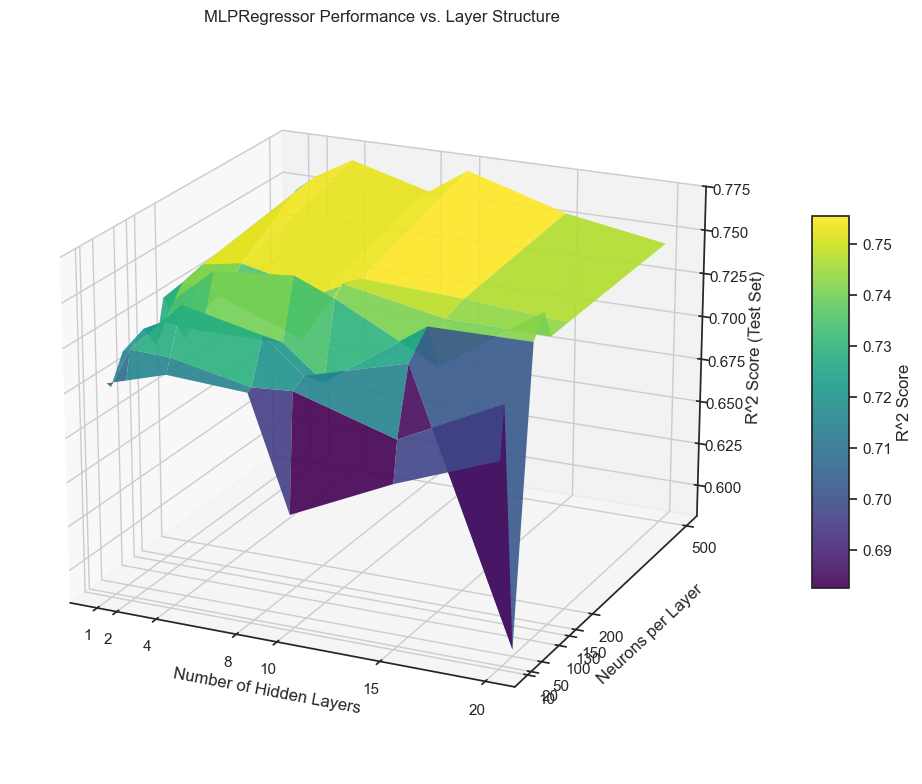

In [95]:
# Drwaw 3D surface plot

X_layers = np.array(results_df['n_layers'])
Y_neurons = np.array(results_df['neurons'])
Z_r2 = np.array(results_df['r2_score'])


unique_layers = np.unique(X_layers)
unique_neurons = np.unique(Y_neurons)


X_grid, Y_grid = np.meshgrid(unique_layers, unique_neurons)

Z_grid = Z_r2.reshape(len(unique_layers), len(unique_neurons)).T


fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis',
                        linewidth=0, antialiased=True, alpha=0.9)

ax.set_xlabel('Number of Hidden Layers')
ax.set_ylabel('Neurons per Layer')
ax.set_zlabel('R^2 Score (Test Set)')
ax.set_title('MLPRegressor Performance vs. Layer Structure')

fig.colorbar(surf, shrink=0.5, aspect=10, label='R^2 Score')

ax.set_xticks(unique_layers)
ax.set_yticks(unique_neurons)


ax.view_init(elev=20, azim=-65)

plt.tight_layout()
plt.show()

The overall trend of the graph seems not to have changed significantly. It shows the best results around 8 hidden layers and around 130 neurons per layer.

In [96]:
y_pred_df = pd.DataFrame(y_pred, index=y_test_scaled_extended.index, columns=["revenue"])

y_test_scaled_test =  y_test_scaled_extended[y_test_scaled_extended["revenue"] < 3]
y_pred_test =  y_pred_df.loc[y_test_scaled_test.index]
# display(y_test_scaled_test[y_test_scaled_test.isna().any(axis=1)])
# display(y_pred_test[y_pred_test.isna().any(axis=1)])

mse = mean_squared_error(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())
r2 = r2_score(y_test_scaled_test.values.ravel(), y_pred_test.values.ravel())

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.1003
Root Mean Squared Error (RMSE): 0.3167
Mean Absolute Error (MAE): 0.1723
R-squared (R2): 0.6219


As expected, when checking only the values less than or equal to 3, the performance drops drastically. I suspect that the extreme values might have contaminated the R2 score.

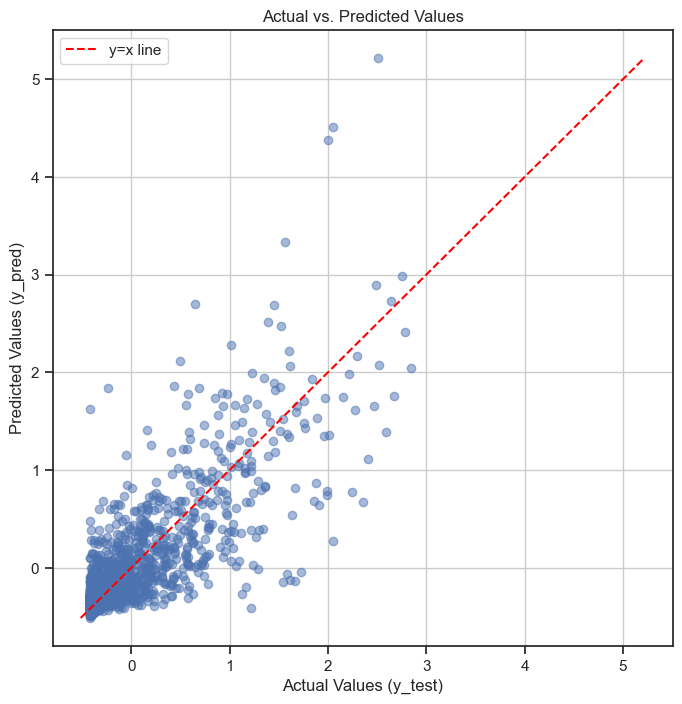

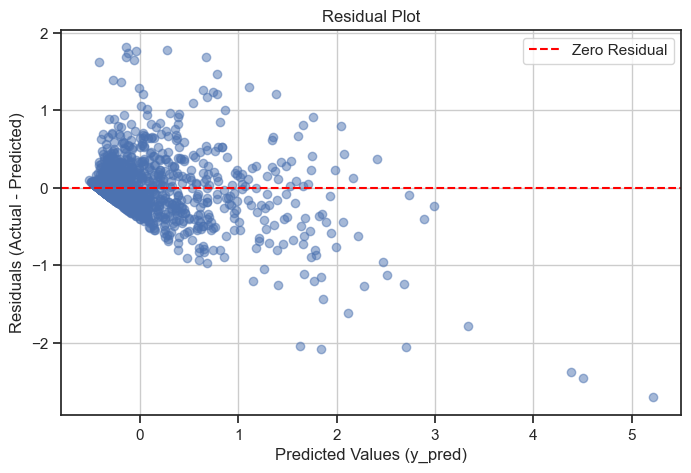

In [97]:

plt.figure(figsize=(8, 8))
plt.scatter(y_test_scaled_test, y_pred_test, alpha=0.5)
plt.plot([min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         [min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         color='red', linestyle='--', label='y=x line') # y=x 직선
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

residuals = y_test_scaled_test.values.ravel() - y_pred_test.values.ravel()
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual') # 잔차 0 기준선
plt.xlabel("Predicted Values (y_pred)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.grid(True)
plt.show()

As expected, it tends to overestimate compared to the original values.

So this time, I’ll exclude from the embedded dataset all entries with revenue ≥ 3 and train to find the optimal number of neurons.

Since the dimensionality has increased significantly, I think the optimal hidden layer size might differ, so I’ll determine the new optimal number of neurons.

In [98]:
y_train_scaled_pruned_extended = y_train_scaled_extended[y_train_scaled_extended["revenue"] < 3]
X_train_scaled_pruned_extended = X_train_scaled_extended.loc[y_train_scaled_pruned_extended.index]

# I’ll prune the test set so that it’s only used for comparing pruning training results.
y_test_scaled_pruned_extended = y_test_scaled_extended[y_test_scaled_extended["revenue"] < 3]
X_test_scaled_pruned_extended = X_test_scaled_extended.loc[y_test_scaled_pruned_extended.index]

In [99]:
X_test_scaled_pruned_extended

,vote_average,vote_count,runtime,budget,popularity,original_language_ar,original_language_bn,original_language_cn,original_language_de,original_language_en,...,overview_embed_379,overview_embed_380,overview_embed_381,overview_embed_382,overview_embed_383,year_scaled,month_sin,month_cos,day_sin,day_cos
id,,,,,,,,,,,,,,,,,,,,,
86837,0.912894,0.010367,0.670002,-0.368430,-0.065673,-1,-1,-1,-1,-1,...,0.034698,-0.019942,-0.032606,0.045311,-0.045957,0.783784,-1.000000e+00,-1.836970e-16,-0.790776,-0.612106
811631,-0.137413,-0.434755,-0.204703,-0.477132,-0.009842,-1,-1,-1,-1,1,...,0.074567,0.045572,-0.032125,-0.002221,-0.012511,0.963964,1.000000e+00,6.123234e-17,-0.937752,0.347305
100922,-0.347365,-0.493460,-0.263016,-0.287233,-0.223623,-1,-1,-1,-1,1,...,0.010428,0.045730,0.007974,-0.004835,0.029599,0.135135,8.660254e-01,-5.000000e-01,0.848644,0.528964
473234,0.657134,-0.472741,2.419411,-0.581115,-0.161893,-1,-1,-1,-1,-1,...,0.081367,-0.002125,-0.003637,0.053628,0.006582,0.873874,-8.660254e-01,-5.000000e-01,-0.937752,0.347305
966121,-3.323779,-0.501748,-2.624718,-0.601514,-0.282815,-1,-1,-1,-1,1,...,-0.017590,0.001702,0.001737,-0.008382,-0.020113,0.945946,-8.660254e-01,5.000000e-01,0.101168,-0.994869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
541526,-0.597126,-0.501057,-0.233859,4.637005,-0.269258,-1,-1,-1,-1,1,...,0.050860,-0.051834,-0.014900,-0.048802,-0.022366,0.639640,1.224647e-16,-1.000000e+00,-0.724793,0.688967
1965,0.221415,-0.075964,0.086866,0.970020,0.054004,-1,-1,-1,-1,1,...,0.008094,0.069863,-0.063458,0.066816,-0.042410,0.531532,1.224647e-16,-1.000000e+00,0.848644,0.528964
624779,-0.111782,-0.430957,-0.350487,-0.575353,-0.150874,-1,-1,-1,-1,1,...,-0.054516,0.044231,0.010933,0.023985,0.006099,0.909910,-1.000000e+00,-1.836970e-16,-0.897805,-0.440394


In [100]:
# Emergency break point

In [101]:
# n_layers_range = [1,2,4,5,6,7,8,10,12,15,17,20] # 예: 1개 ~ 4개 층
# neurons_per_layer_range = [10,20,50,70,100,120,130,140,150,180,200,300,400,500] # 예: 10, 40, 70, 100개 뉴런


# results_neuron_layer = []


# print("\nStart to train MLPRegressor...")
# total_combinations = len(n_layers_range) * len(neurons_per_layer_range)
# count = 0

# for n_layers in n_layers_range:
#     for neurons in neurons_per_layer_range:
#         count += 1
#         print(f"Progression: {count}/{total_combinations} - layer: {n_layers}, neurons: {neurons}")


#         hidden_layer_config = tuple([neurons] * n_layers)

#         mlp_regressor = MLPRegressor(
#             hidden_layer_sizes=hidden_layer_config,  
#             activation=activation_final,
#             solver=solver_final,
#             alpha=alpha_final,
#             max_iter=10000, 
#             early_stopping=True,
#             validation_fraction=0.1,
#             n_iter_no_change=10,
#             learning_rate_init = learning_rate_final,
#             learning_rate = 'adaptive',
#             random_state=random_state,
#             verbose=False 
#         )

#         scores = cross_val_score(mlp_regressor, X_train_scaled_pruned_extended, y_train_scaled_pruned_extended.values.ravel(), cv=5, scoring='r2')
#         print("Score of each folds:", scores)
#         print("Mean score:", np.mean(scores))


#         results_neuron_layer.append({'n_layers': n_layers, 'neurons': neurons, 'r2_score': np.mean(scores)})



In [102]:
# results_df = pd.DataFrame(results_neuron_layer)
# results_df.to_csv('./result/mlp_regressor_results_pruned_extended.csv', index=False)

In [103]:
results_df = pd.read_csv('./result/mlp_regressor_results_pruned_extended.csv')
results_df

,n_layers,neurons,r2_score
0,1,10,0.662839
1,1,20,0.666989
2,1,50,0.677840
3,1,70,0.667670
4,1,100,0.675436
...,...,...,...
163,20,180,0.680568
164,20,200,0.690494
165,20,300,0.679914
166,20,400,0.692766


Now that training is complete, I’ll create a graph this time as well to compare.

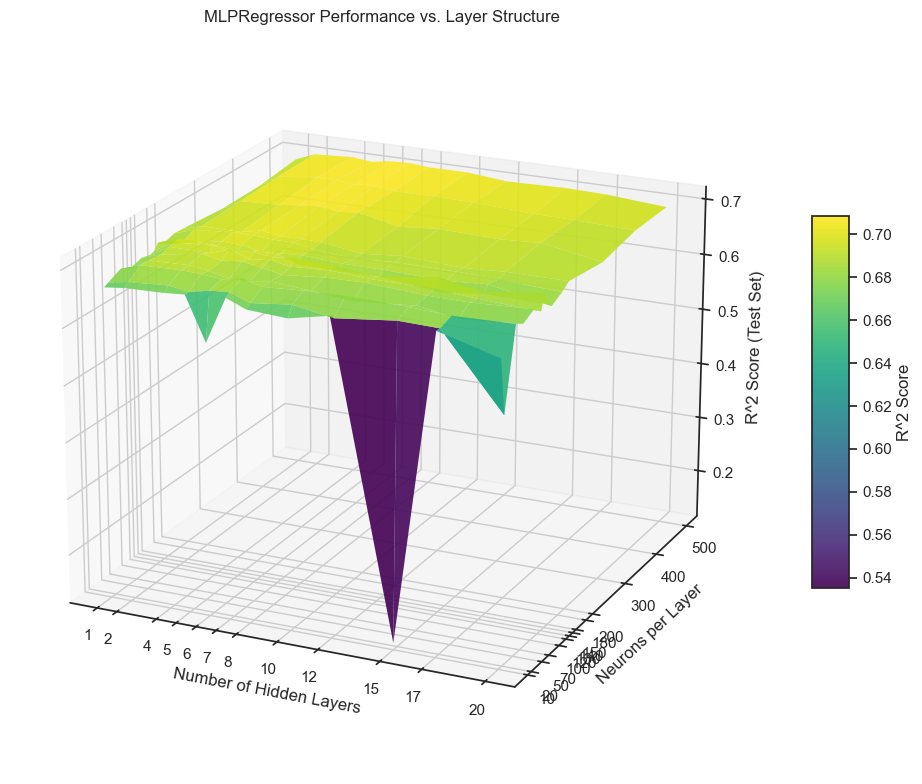

In [104]:

X_layers = np.array(results_df['n_layers'])
Y_neurons = np.array(results_df['neurons'])
Z_r2 = np.array(results_df['r2_score'])


unique_layers = np.unique(X_layers)
unique_neurons = np.unique(Y_neurons)

X_grid, Y_grid = np.meshgrid(unique_layers, unique_neurons)


Z_grid = Z_r2.reshape(len(unique_layers), len(unique_neurons)).T 


fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')


surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis',
                        linewidth=0, antialiased=True, alpha=0.9)

ax.set_xlabel('Number of Hidden Layers')
ax.set_ylabel('Neurons per Layer')
ax.set_zlabel('R^2 Score (Test Set)')
ax.set_title('MLPRegressor Performance vs. Layer Structure')


fig.colorbar(surf, shrink=0.5, aspect=10, label='R^2 Score')

ax.set_xticks(unique_layers)
ax.set_yticks(unique_neurons)

ax.view_init(elev=20, azim=-65)

plt.tight_layout()
plt.show()

Looking at this graph, it seems that the more layers per neuron, the better the model’s performance, while the number of hidden layers doesn’t have much impact—and actually appears to decrease performance when there are too many. However, since the R² curve hasn’t plateaued yet, I’ll split the range appropriately and run the test again.

In [105]:
# n_layers_range = range(2, 13)
# neurons_per_layer_range = range(200, 751, 50)

# results_neuron_layer = []

# print("\nStart to train MLPRegressor...")
# total_combinations = len(n_layers_range) * len(neurons_per_layer_range)
# count = 0

# for n_layers in n_layers_range:
#     for neurons in neurons_per_layer_range:
#         count += 1
#         print(f"Progression: {count}/{total_combinations} - layer: {n_layers}, neurons: {neurons}")

#         hidden_layer_config = tuple([neurons] * n_layers)

#         mlp_regressor = MLPRegressor(
#             hidden_layer_sizes=hidden_layer_config, 
#             activation=activation_final,
#             solver=solver_final,
#             alpha=alpha_final, 
#             max_iter=10000,
#             early_stopping=True,
#             validation_fraction=0.1,
#             n_iter_no_change=10,
#             learning_rate_init = learning_rate_final,
#             learning_rate = 'adaptive',
#             random_state=random_state,
#             verbose=False
#         )

#         scores = cross_val_score(mlp_regressor, X_train_scaled_pruned_extended, y_train_scaled_pruned_extended.values.ravel(), cv=5, scoring='r2')
#         print("Score of each folds:", scores)
#         print("Mean score:", np.mean(scores))


#         results_neuron_layer.append({'n_layers': n_layers, 'neurons': neurons, 'r2_score': np.mean(scores)})

#         print(results_neuron_layer[-1])



In [106]:
# results_df = pd.DataFrame(results_neuron_layer)
# results_df.to_csv('./result/mlp_regressor_results_pruned_extended2.csv', index=False)

In [107]:
results_df = pd.read_csv('./result/mlp_regressor_results_pruned_extended2.csv')
results_df

,n_layers,neurons,r2_score
0,2,200,0.687256
1,2,250,0.681767
2,2,300,0.691486
3,2,350,0.691632
4,2,400,0.688901
...,...,...,...
127,12,550,0.694648
128,12,600,0.687204
129,12,650,0.667627
130,12,700,0.662828


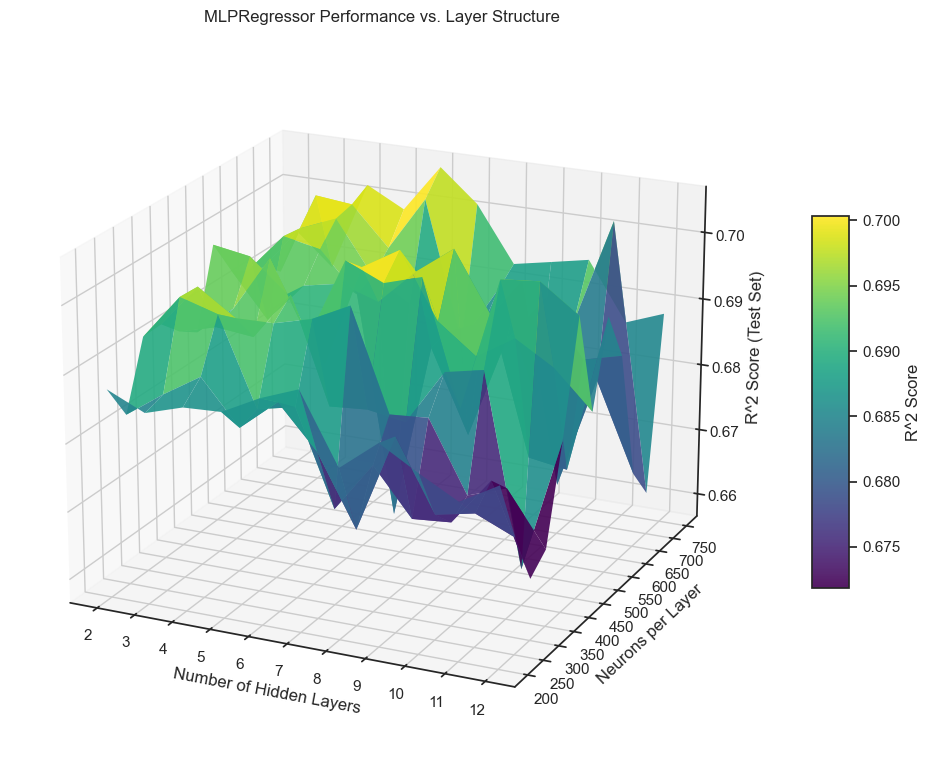

In [108]:

X_layers = np.array(results_df['n_layers'])
Y_neurons = np.array(results_df['neurons'])
Z_r2 = np.array(results_df['r2_score'])


unique_layers = np.unique(X_layers)
unique_neurons = np.unique(Y_neurons)


X_grid, Y_grid = np.meshgrid(unique_layers, unique_neurons)

Z_grid = Z_r2.reshape(len(unique_layers), len(unique_neurons)).T

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis',
                        linewidth=0, antialiased=True, alpha=0.9)


ax.set_xlabel('Number of Hidden Layers')
ax.set_ylabel('Neurons per Layer')
ax.set_zlabel('R^2 Score (Test Set)')
ax.set_title('MLPRegressor Performance vs. Layer Structure')

fig.colorbar(surf, shrink=0.5, aspect=10, label='R^2 Score')

ax.set_xticks(unique_layers)
ax.set_yticks(unique_neurons)

ax.view_init(elev=20, azim=-65)

plt.tight_layout()
plt.show()

Although we’ve surpassed the formidable 0.7 barrier, we still haven’t reached the summit. I’ll adjust the range and test again.

In [109]:
max_R2_row = results_df.nlargest(1, 'r2_score')
display(max_R2_row)
neurons = max_R2_row['neurons'].values[0]
n_layers = max_R2_row['n_layers'].values[0]

display(results_df[(results_df['neurons'] == 750 )])

,n_layers,neurons,r2_score
59,6,750,0.705846


,n_layers,neurons,r2_score
11,2,750,0.693029
23,3,750,0.688124
35,4,750,0.701611
47,5,750,0.698660
59,6,750,0.705846
71,7,750,0.701003
83,8,750,0.692695
95,9,750,0.693809
107,10,750,0.694944
119,11,750,0.686295


In [110]:
# n_layers_range = range(4, 9)
# neurons_per_layer_range = range(800, 1201, 50)


# results_neuron_layer = []


# print("\nStart to train MLPRegressor...")
# total_combinations = len(n_layers_range) * len(neurons_per_layer_range)
# count = 0

# for n_layers in n_layers_range:
#     for neurons in neurons_per_layer_range:
#         count += 1
#         print(f"Progression: {count}/{total_combinations} - layer: {n_layers}, neurons: {neurons}")

#         # 예: n_layers=3, neurons=50 -> (50, 50, 50)
#         hidden_layer_config = tuple([neurons] * n_layers)

#         mlp_regressor = MLPRegressor(
#             hidden_layer_sizes=hidden_layer_config,
#             activation=activation_final,
#             solver=solver_final,
#             alpha=alpha_final,
#             max_iter=10000,
#             early_stopping=True,
#             validation_fraction=0.1,
#             n_iter_no_change=10,
#             learning_rate_init = learning_rate_final,
#             learning_rate = 'adaptive',
#             random_state=random_state,
#             verbose=False
#         )

#         scores = cross_val_score(mlp_regressor, X_train_scaled_pruned_extended, y_train_scaled_pruned_extended.values.ravel(), cv=5, scoring='r2')
#         print("Score of each folds:", scores)
#         print("Mean score:", np.mean(scores))


#         results_neuron_layer.append({'n_layers': n_layers, 'neurons': neurons, 'r2_score': np.mean(scores)})

#         print(results_neuron_layer[-1])



In [111]:
# results_df = pd.DataFrame(results_neuron_layer)
# results_df.to_csv('./result/mlp_regressor_results_pruned_extended3.csv', index=False)

In [112]:
results_df = pd.read_csv('./result/mlp_regressor_results_pruned_extended3.csv')
results_df.sample(10)

,n_layers,neurons,r2_score
17,5,1200,0.688951
19,6,850,0.703743
10,5,850,0.691340
25,6,1150,0.686992
28,7,850,0.687805
16,5,1150,0.699724
44,8,1200,0.702627
12,5,950,0.697750
9,5,800,0.694388
40,8,1000,0.700408


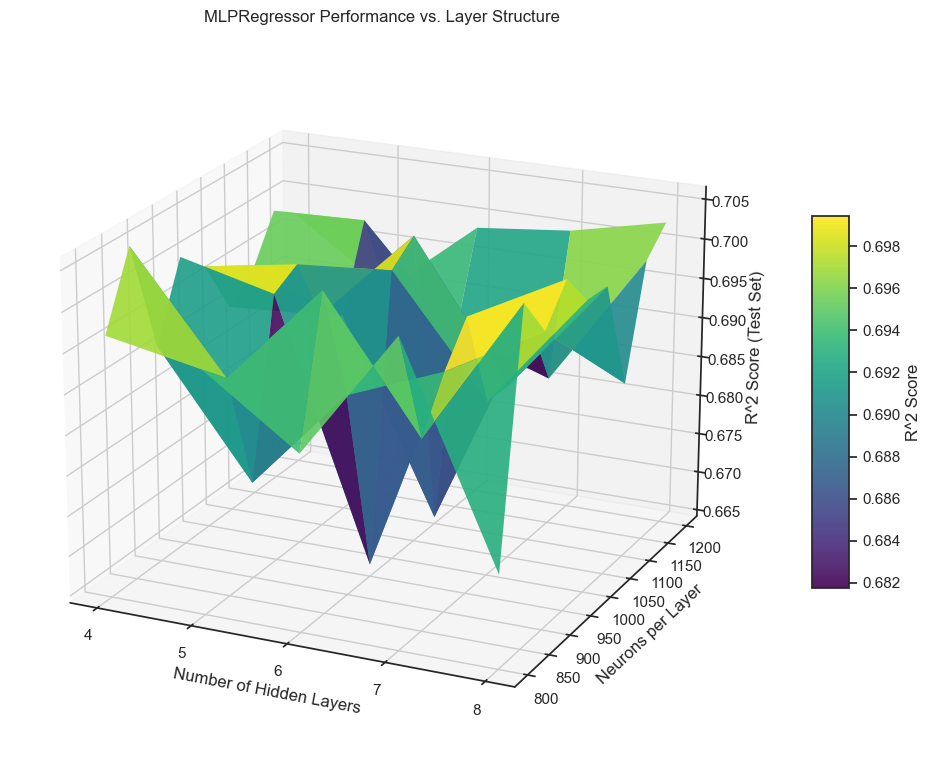

In [113]:

X_layers = np.array(results_df['n_layers'])
Y_neurons = np.array(results_df['neurons'])
Z_r2 = np.array(results_df['r2_score'])


unique_layers = np.unique(X_layers)
unique_neurons = np.unique(Y_neurons)


X_grid, Y_grid = np.meshgrid(unique_layers, unique_neurons)

Z_grid = Z_r2.reshape(len(unique_layers), len(unique_neurons)).T 


fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')


surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis',
                        linewidth=0, antialiased=True, alpha=0.9)

ax.set_xlabel('Number of Hidden Layers')
ax.set_ylabel('Neurons per Layer')
ax.set_zlabel('R^2 Score (Test Set)')
ax.set_title('MLPRegressor Performance vs. Layer Structure')



fig.colorbar(surf, shrink=0.5, aspect=10, label='R^2 Score')

ax.set_xticks(unique_layers)
ax.set_yticks(unique_neurons)

ax.view_init(elev=20, azim=-65)

plt.tight_layout()
plt.show()

Unfortunately, it seems that what we observed was indeed the summit of the mountain.

In [114]:
max_R2_row = results_df.nlargest(1, 'r2_score')
display(max_R2_row)

,n_layers,neurons,r2_score
37,8,850,0.705752


The configuration we identified—six hidden layers with 750 neurons per layer—yields the best performance. Since it consumes fewer computing resources and delivers superior results, I’ll finalize that setup.

In [115]:
neurons = 750
n_layers = 6

hidden_layer_config_final_extended = tuple([neurons] * n_layers)
print(hidden_layer_config_final_extended)

(750, 750, 750, 750, 750, 750)


In [116]:

movie_extended_mlp_regressor = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final_extended, 
    activation=activation_final,
    solver=solver_final,
    alpha=alpha_final,
    max_iter=2000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=True
)


movie_extended_mlp_regressor.fit(X_train_scaled_pruned_extended, y_train_scaled_pruned_extended.values.ravel())

Iteration 1, loss = 0.14166659
Validation score: 0.242757
Iteration 2, loss = 0.10338807
Validation score: 0.519847
Iteration 3, loss = 0.07268229
Validation score: 0.652648
Iteration 4, loss = 0.06139818
Validation score: 0.692854
Iteration 5, loss = 0.05774962
Validation score: 0.707210
Iteration 6, loss = 0.05617791
Validation score: 0.715311
Iteration 7, loss = 0.05521049
Validation score: 0.717913
Iteration 8, loss = 0.05430654
Validation score: 0.725096
Iteration 9, loss = 0.05340562
Validation score: 0.726520
Iteration 10, loss = 0.05290176
Validation score: 0.729007
Iteration 11, loss = 0.05209024
Validation score: 0.735771
Iteration 12, loss = 0.05166498
Validation score: 0.736931
Iteration 13, loss = 0.05034072
Validation score: 0.740840
Iteration 14, loss = 0.04954939
Validation score: 0.739050
Iteration 15, loss = 0.04925512
Validation score: 0.744092
Iteration 16, loss = 0.04838784
Validation score: 0.744650
Iteration 17, loss = 0.04765569
Validation score: 0.751807
Iterat

MLPRegressor(alpha=0.001, early_stopping=True,
             hidden_layer_sizes=(750, 750, 750, 750, 750, 750),
             learning_rate='adaptive', learning_rate_init=1e-05, max_iter=2000,
             random_state=42, verbose=True)

## Model Evaluation

In [117]:
# 테스트 데이터로 예측
y_pred = movie_extended_mlp_regressor.predict(X_test_scaled_pruned_extended)

y_pred_df = pd.DataFrame(y_pred, index=y_test_scaled_pruned_extended.index, columns=["revenue"])

mse = mean_squared_error(y_test_scaled_pruned_extended.values.ravel(), y_pred_df.values.ravel())
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test_scaled_pruned_extended.values.ravel(), y_pred_df.values.ravel())
r2 = r2_score(y_test_scaled_pruned_extended.values.ravel(), y_pred_df.values.ravel())

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.0780
Root Mean Squared Error (RMSE): 0.2793
Mean Absolute Error (MAE): 0.1553
R-squared (R2): 0.7058


Right now, the validation score is close to 0.76, but the test set score is 0.70. Since overfitting is suspected, I’ll check the train set values.

In [118]:
# 테스트 데이터로 예측
test_pred = movie_extended_mlp_regressor.predict(X_train_scaled_pruned_extended)

test_pred = pd.DataFrame(test_pred, index=y_train_scaled_pruned_extended.index, columns=["revenue"])

mse = mean_squared_error(y_train_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_train_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())
r2 = r2_score(y_train_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.0486
Root Mean Squared Error (RMSE): 0.2205
Mean Absolute Error (MAE): 0.1272
R-squared (R2): 0.8372


I can clearly see that it’s overfitting.

This time, I’ll increase the alpha value to help prevent overfitting.

In [119]:

# MLPRegressor 모델 정의
overfit_test = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final_extended,  # 예: 1000개 뉴런 -> 50개 뉴런의 20개 은닉층
    activation=activation_final,
    solver=solver_final,
    alpha=alpha_final * 100,
    max_iter=500, # 충분한 학습 반복
    early_stopping=True, # 조기 종료 사용
    validation_fraction=0.1, # 학습 데이터의 10%를 검증용으로 사용
    n_iter_no_change=10, # 10번 반복 동안 성능 개선 없으면 종료
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=True # 학습 과정 출력 여부 (True로 설정하면 과정 보임)
)

# 모델 학습
overfit_test.fit(X_train_scaled_pruned_extended, y_train_scaled_pruned_extended.values.ravel())

Iteration 1, loss = 1.21748440
Validation score: 0.236462
Iteration 2, loss = 1.16913318
Validation score: 0.508456
Iteration 3, loss = 1.12730642
Validation score: 0.646533
Iteration 4, loss = 1.10462544
Validation score: 0.688646
Iteration 5, loss = 1.08999296
Validation score: 0.703885
Iteration 6, loss = 1.07772586
Validation score: 0.712472
Iteration 7, loss = 1.06626221
Validation score: 0.714636
Iteration 8, loss = 1.05503504
Validation score: 0.721441
Iteration 9, loss = 1.04398251
Validation score: 0.722156
Iteration 10, loss = 1.03342676
Validation score: 0.724838
Iteration 11, loss = 1.02279707
Validation score: 0.731614
Iteration 12, loss = 1.01263465
Validation score: 0.733033
Iteration 13, loss = 1.00167064
Validation score: 0.736430
Iteration 14, loss = 0.99148317
Validation score: 0.733791
Iteration 15, loss = 0.98189526
Validation score: 0.739411
Iteration 16, loss = 0.97189028
Validation score: 0.740385
Iteration 17, loss = 0.96209456
Validation score: 0.745961
Iterat

MLPRegressor(alpha=0.1, early_stopping=True,
             hidden_layer_sizes=(750, 750, 750, 750, 750, 750),
             learning_rate='adaptive', learning_rate_init=1e-05, max_iter=500,
             random_state=42, verbose=True)

In [120]:
# 테스트 데이터로 예측
test_pred = overfit_test.predict(X_test_scaled_pruned_extended)

test_pred = pd.DataFrame(test_pred, index=y_test_scaled_pruned_extended.index, columns=["revenue"])

mse = mean_squared_error(y_test_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())
r2 = r2_score(y_test_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())

print("Test Set------------")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Test Set------------
Mean Squared Error (MSE): 0.0771
Root Mean Squared Error (RMSE): 0.2777
Mean Absolute Error (MAE): 0.1524
R-squared (R2): 0.7092


In [121]:
# 트레인 데이터로 예측
test_pred = overfit_test.predict(X_train_scaled_pruned_extended)

test_pred = pd.DataFrame(test_pred, index=y_train_scaled_pruned_extended.index, columns=["revenue"])

mse = mean_squared_error(y_train_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())
rmse = np.sqrt(mse) # 또는 mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_train_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())
r2 = r2_score(y_train_scaled_pruned_extended.values.ravel(), test_pred.values.ravel())

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Squared Error (MSE): 0.0538
Root Mean Squared Error (RMSE): 0.2320
Mean Absolute Error (MAE): 0.1315
R-squared (R2): 0.8198


It still shows the same level of overfitting, so it seems that it’s not just because of overtraining but rather due to the input layer’s dimensionality being too high.

Even though overfitting is apparent, since the test set produced the desired results, I’ll be satisfied with this and proceed.

Now I’ll draw a scatter plot to examine the overall trend of the values.

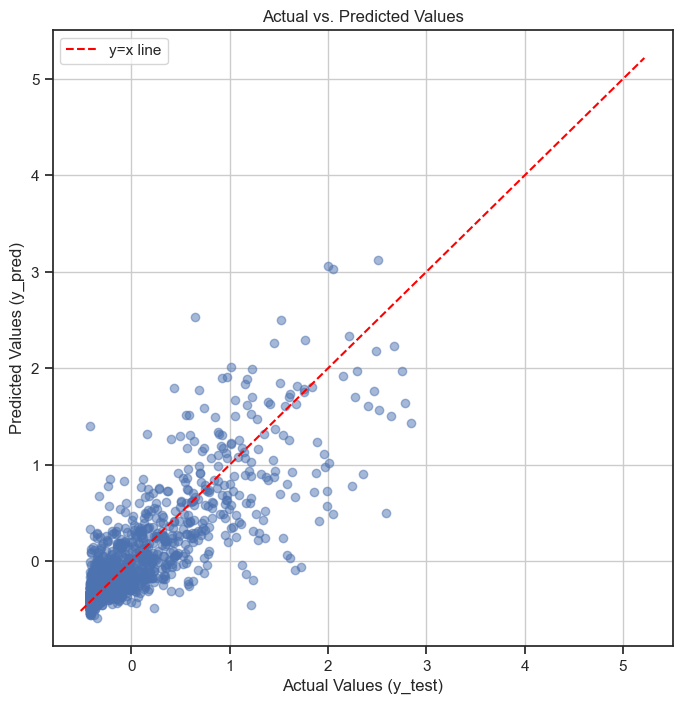

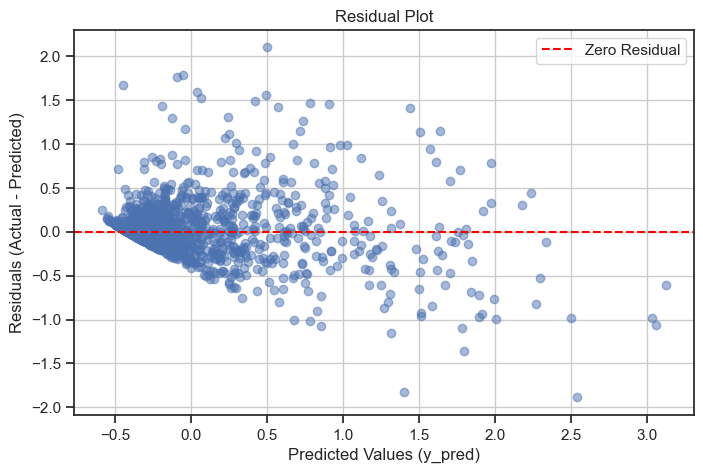

In [122]:

plt.figure(figsize=(8, 8))
plt.scatter(y_test_scaled_pruned_extended, y_pred_df, alpha=0.5)
plt.plot([min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         [min(y_test_scaled_test.values.ravel().min(), y_pred_test.values.ravel().min()), max(y_test_scaled_test.values.ravel().max(), y_pred_test.values.ravel().max())],
         color='red', linestyle='--', label='y=x line')
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True)
plt.show()


residuals = y_test_scaled_pruned_extended.values.ravel() - y_pred_df.values.ravel()
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_df, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual')
plt.xlabel("Predicted Values (y_pred)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.grid(True)
plt.show()

Overall, the point distribution looks similar to the non‑embedded case: there’s a strong tendency to over‑predict revenue for low‑revenue films and under‑predict for high‑revenue films.

### Linar Regression

First, I’ll create the dataset for regression. Since I believe the embedded dataset won’t exhibit linearity with the target, I’ll only add the dates to the original dataset.

In [123]:
X_train_scaled_linear = X_train_scaled_pruned.iloc[:, 0:5]
X_test_scaled_linear = X_test_scaled_pruned.iloc[:, 0:5]
y_train_scaled_linear = y_train_scaled_pruned
y_test_scaled_linear = y_test_scaled_pruned

In [124]:
movie_revenue_linear = LinearRegression(fit_intercept=True)
movie_revenue_linear.fit(X_train_scaled_linear, y_train_scaled_linear.values.ravel())

print(f"coefficients/slopes: {movie_revenue_linear.coef_}")
print(f"intercept: {movie_revenue_linear.intercept_}")

coefficients/slopes: [-1.41066412e-04  3.26649162e-01  2.72213724e-03  3.17753814e-01
  1.66780490e-02]
intercept: -0.06302791265433934


In [125]:
y_pred = movie_revenue_linear.predict(X_train_scaled_linear)

r2 = r2_score(y_train_scaled_linear, y_pred)
rmse = root_mean_squared_error(y_train_scaled_linear, y_pred)
mae = mean_absolute_error(y_train_scaled_linear, y_pred)

print("---")
print(f"R^2 Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

---
R^2 Score: 0.6590
Mean Squared Error (MSE): 0.0538
Root Mean Squared Error (RMSE): 0.3191
Mean Absolute Error (MAE): 0.1708


In [126]:
y_pred = movie_revenue_linear.predict(X_test_scaled_linear)

r2 = r2_score(y_test_scaled_linear, y_pred)
rmse = root_mean_squared_error(y_test_scaled_linear, y_pred)
mae = mean_absolute_error(y_test_scaled_linear, y_pred)

print("---")
print(f"R^2 Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

---
R^2 Score: 0.6349
Mean Squared Error (MSE): 0.0538
Root Mean Squared Error (RMSE): 0.3112
Mean Absolute Error (MAE): 0.1667


Although the performance doesn’t match that of the extended neural network model, there doesn’t appear to be any clear overfitting issue.

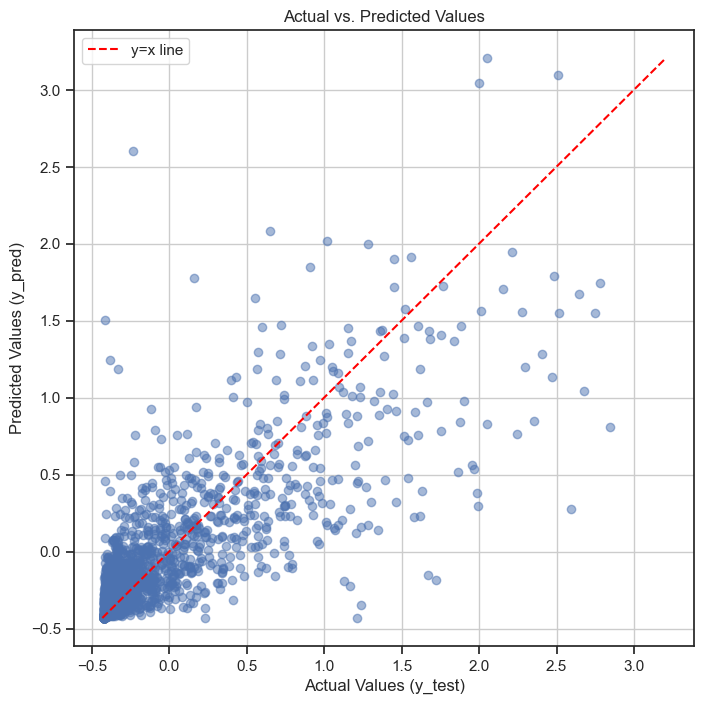

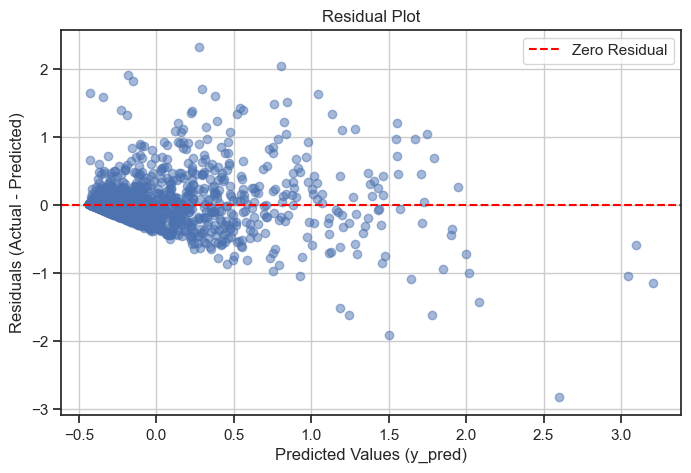

In [127]:
y_pred_df = pd.DataFrame(y_pred, index=y_test_scaled_linear.index, columns=["revenue"])


plt.figure(figsize=(8, 8))
plt.scatter(y_test_scaled_linear, y_pred_df, alpha=0.5)
plt.plot([min(y_test_scaled_linear.values.ravel().min(), y_pred_df.values.ravel().min()), max(y_test_scaled_linear.values.ravel().max(), y_pred_df.values.ravel().max())],
         [min(y_test_scaled_linear.values.ravel().min(), y_pred_df.values.ravel().min()), max(y_test_scaled_linear.values.ravel().max(), y_pred_df.values.ravel().max())],
         color='red', linestyle='--', label='y=x line') # y=x 직선
plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True)
plt.show()


residuals = y_test_scaled_linear.values.ravel() - y_pred_df.values.ravel()
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_df, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual') 
plt.xlabel("Predicted Values (y_pred)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.grid(True)
plt.show()

Overall, the inferred values exhibit a pattern similar to the neural network: low values tend to be predicted even lower, and high values even higher.

## Model Comparision (Base model vs extended model vs linear regression)

Now, we’ll formally compare the original model we trained with the two refined models—one using embeddings and one with dates added.

In [128]:
movie_revenue_mlp_regressor = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final,
    activation=activation_final,
    solver= solver_final,
    alpha=alpha_final,
    max_iter=10000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=False
)

movie_revenue_mlp_regressor.fit(X_train_scaled_pruned, y_train_scaled_pruned.values.ravel())

MLPRegressor(alpha=0.001, early_stopping=True,
             hidden_layer_sizes=(130, 130, 130, 130, 130, 130, 130, 130),
             learning_rate='adaptive', learning_rate_init=1e-05, max_iter=10000,
             random_state=42)

In [129]:


movie_revenue_extended_mlp_regressor = MLPRegressor(
    hidden_layer_sizes=hidden_layer_config_final_extended, 
    activation=activation_final,
    solver=solver_final,
    alpha=alpha_final,
    max_iter=2000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    learning_rate_init = learning_rate_final,
    learning_rate = 'adaptive',
    random_state=random_state,
    verbose=True # 학습 과정 출력 여부 (True로 설정하면 과정 보임)
)

# 모델 학습
movie_revenue_extended_mlp_regressor.fit(X_train_scaled_pruned_extended, y_train_scaled_pruned_extended.values.ravel())

Iteration 1, loss = 0.14166659
Validation score: 0.242757
Iteration 2, loss = 0.10338807
Validation score: 0.519847
Iteration 3, loss = 0.07268229
Validation score: 0.652648
Iteration 4, loss = 0.06139818
Validation score: 0.692854
Iteration 5, loss = 0.05774962
Validation score: 0.707210
Iteration 6, loss = 0.05617791
Validation score: 0.715311
Iteration 7, loss = 0.05521049
Validation score: 0.717913
Iteration 8, loss = 0.05430654
Validation score: 0.725096
Iteration 9, loss = 0.05340562
Validation score: 0.726520
Iteration 10, loss = 0.05290176
Validation score: 0.729007
Iteration 11, loss = 0.05209024
Validation score: 0.735771
Iteration 12, loss = 0.05166498
Validation score: 0.736931
Iteration 13, loss = 0.05034072
Validation score: 0.740840
Iteration 14, loss = 0.04954939
Validation score: 0.739050
Iteration 15, loss = 0.04925512
Validation score: 0.744092
Iteration 16, loss = 0.04838784
Validation score: 0.744650
Iteration 17, loss = 0.04765569
Validation score: 0.751807
Iterat

MLPRegressor(alpha=0.001, early_stopping=True,
             hidden_layer_sizes=(750, 750, 750, 750, 750, 750),
             learning_rate='adaptive', learning_rate_init=1e-05, max_iter=2000,
             random_state=42, verbose=True)

First, I’ll compare using the dataset that includes the extreme, unfiltered revenue values.

In [130]:
y_pred_neural = movie_revenue_mlp_regressor.predict(X_test_scaled_pruned)
y_pred_neural_extended = movie_revenue_extended_mlp_regressor.predict(X_test_scaled_pruned_extended)
y_pred_linear = movie_revenue_linear.predict(X_test_scaled_linear)

In [131]:
# --- 2. 성능 지표 계산 및 출력 ---
print(f"--- Base Model Performance ---")
r2_1 = r2_score(y_test_scaled_pruned, y_pred_neural)
rmse_1 = root_mean_squared_error(y_test_scaled_pruned, y_pred_neural)
mae_1 = mean_absolute_error(y_test_scaled_pruned, y_pred_neural)
n = X_test_scaled.shape[0]  # test set sample size
p = X_train_scaled.shape[1]  # number of features used in training
adjusted_r2_1 = 1 - (1 - r2_1) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_1:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_1:.4f}")
print(f"RMSE: {rmse_1:.4f}")
print(f"MAE: {mae_1:.4f}")


print(f"\n--- Extended Model Performance ---")
r2_2 = r2_score(y_test_scaled_pruned_extended, y_pred_neural_extended)
rmse_2 = root_mean_squared_error(y_test_scaled_pruned_extended, y_pred_neural_extended)
mae_2 = mean_absolute_error(y_test_scaled_pruned_extended, y_pred_neural_extended)
n = X_test_scaled_extended.shape[0]  # test set sample size
p = X_train_scaled_extended.shape[1]  # number of features used in training
adjusted_r2_2 = 1 - (1 - r2_2) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_2:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_2:.4f}")
print(f"RMSE: {rmse_2:.4f}")
print(f"MAE: {mae_2:.4f}")


print(f"\n--- Linear Regression Performance ---")
r2_3 = r2_score(y_test_scaled_pruned, y_pred_linear)
rmse_3 = root_mean_squared_error(y_test_scaled_pruned, y_pred_linear)
mae_3 = mean_absolute_error(y_test_scaled_pruned, y_pred_linear)
n = X_test_scaled_linear.shape[0]  # test set sample size
p = X_train_scaled_linear.shape[1]  # number of features used in training
adjusted_r2_3 = 1 - (1 - r2_3) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_3:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_3:.4f}")
print(f"RMSE: {rmse_3:.4f}")
print(f"MAE: {mae_3:.4f}")

--- Base Model Performance ---
R^2 Score: 0.6970
Adjusted R^2 Score: 0.6836
RMSE: 0.2835
MAE: 0.1530

--- Extended Model Performance ---
R^2 Score: 0.7058
Adjusted R^2 Score: 0.6185
RMSE: 0.2793
MAE: 0.1553

--- Linear Regression Performance ---
R^2 Score: 0.6349
Adjusted R^2 Score: 0.6340
RMSE: 0.3112
MAE: 0.1667


When we compare the models here, the extended model that included embeddings shows the highest raw performance—but if you look at the Adjusted R² score, it’s heavily penalized and drops sharply. That penalty reflects the huge increase in dimensionality caused by the embeddings despite almost no real performance gain. Given that this model also exhibits fairly severe overfitting, that judgment makes sense.

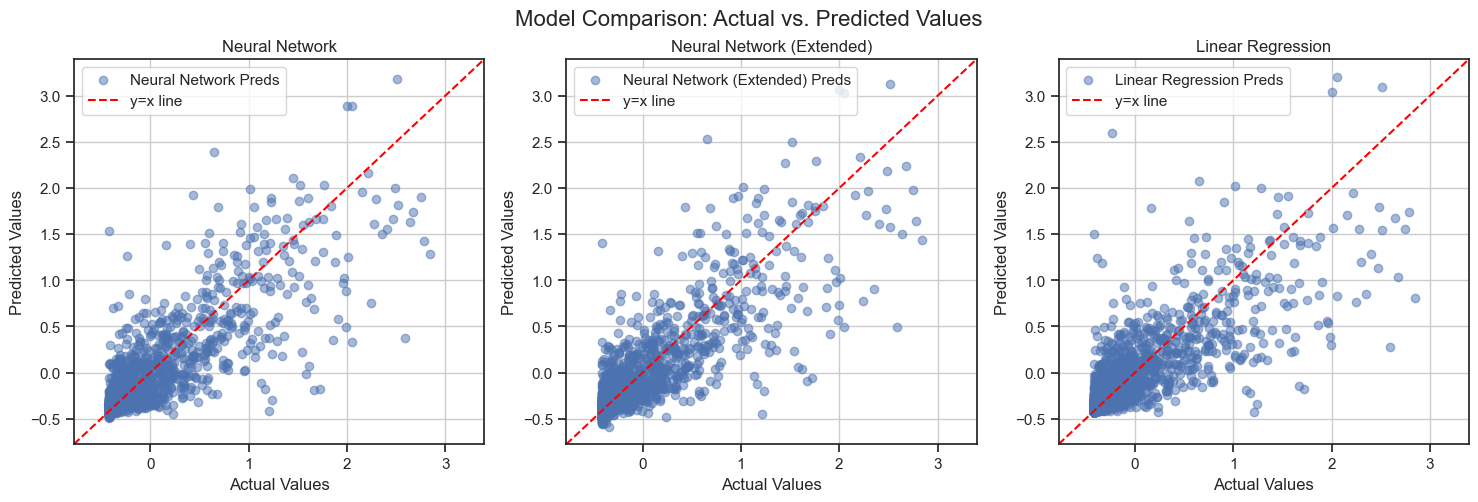

In [132]:
y_test_list = [y_test_scaled_pruned.values.ravel(), y_test_scaled_pruned_extended.values.ravel(), y_test_scaled_pruned.values.ravel()]
y_pred_list = [y_pred_neural, y_pred_neural_extended, y_pred_linear]
model_names = ["Neural Network", "Neural Network (Extended)", "Linear Regression"]


num_models = len(y_test_list)

# --- Calculate overall min/max for consistent axis limits ---
all_values = y_test_list + y_pred_list

y_flat = np.concatenate([df for df in all_values])

# 4) 전체(테스트+예측)에서의 최솟/최댓값
min_val = y_flat.min()
max_val = y_flat.max()

# Add a small padding for better visualization
padding = (max_val - min_val) * 0.05
plot_min = min_val - padding
plot_max = max_val + padding

# --- Create subplots ---
# Adjust layout based on number of models (e.g., 1 row or multiple rows)
ncols = min(num_models, 3) # Max 3 plots per row
nrows = int(np.ceil(num_models / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False) # Ensure axes is always 2D array
axes = axes.flatten() # Flatten axes array for easy iteration

fig.suptitle('Model Comparison: Actual vs. Predicted Values', fontsize=16)

# --- Generate plots for each model ---
for i in range(num_models):
    y_test_current = y_test_list[i]
    y_pred_current = y_pred_list[i]
    model_name = model_names[i]
    ax = axes[i] # Select the appropriate subplot axis
    # Scatter plot
    ax.scatter(y_test_current, y_pred_current, alpha=0.5, label=f'{model_name} Preds')

    # y=x line (Ideal prediction line)
    ax.plot([plot_min, plot_max], [plot_min, plot_max],
            color='red', linestyle='--', label='y=x line')

    # Labels and Title
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title(f"{model_name}")

    # Set consistent limits for comparison
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)

    # Legend and Grid
    ax.legend()
    ax.grid(True)


plt.show()

Looking at this plot, one peculiar feature emerges: in the neural network’s curve around the 0.25 mark, there’s a section beneath the red dot where precision spikes, creating what appears to be a dip. And, fittingly given its score, the graph produced by the linear regression shows the widest scatter of points.

This time, I’ll also check the degree of overfitting.

In [133]:
y_pred_neural = movie_revenue_mlp_regressor.predict(X_train_scaled_pruned)
y_pred_neural_extended = movie_revenue_extended_mlp_regressor.predict(X_train_scaled_pruned_extended)
y_pred_linear = movie_revenue_linear.predict(X_train_scaled_linear)

In [134]:

print(f"--- Base Model Performance ---")
r2_1 = r2_score(y_train_scaled_pruned, y_pred_neural)
rmse_1 = root_mean_squared_error(y_train_scaled_pruned, y_pred_neural)
mae_1 = mean_absolute_error(y_train_scaled_pruned, y_pred_neural)
n = X_train_scaled.shape[0]  # test set sample size
p = X_train_scaled.shape[1]  # number of features used in training
adjusted_r2_1 = 1 - (1 - r2_1) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_1:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_1:.4f}")
print(f"RMSE: {rmse_1:.4f}")
print(f"MAE: {mae_1:.4f}")


print(f"\n--- Extended Model Performance ---")
r2_2 = r2_score(y_train_scaled_pruned_extended, y_pred_neural_extended)
rmse_2 = root_mean_squared_error(y_train_scaled_pruned_extended, y_pred_neural_extended)
mae_2 = mean_absolute_error(y_train_scaled_pruned_extended, y_pred_neural_extended)
n = y_train_scaled_pruned_extended.shape[0]  # test set sample size
p = X_train_scaled_pruned_extended.shape[1]  # number of features used in training
adjusted_r2_2 = 1 - (1 - r2_2) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_2:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_2:.4f}")
print(f"RMSE: {rmse_2:.4f}")
print(f"MAE: {mae_2:.4f}")


print(f"\n--- Linear Regression Performance ---")
r2_3 = r2_score(y_train_scaled_pruned, y_pred_linear)
rmse_3 = root_mean_squared_error(y_train_scaled_pruned, y_pred_linear)
mae_3 = mean_absolute_error(y_train_scaled_pruned, y_pred_linear)
n = X_train_scaled_linear.shape[0]  # test set sample size
p = X_train_scaled_linear.shape[1]  # number of features used in training
adjusted_r2_3 = 1 - (1 - r2_3) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_3:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_3:.4f}")
print(f"RMSE: {rmse_3:.4f}")
print(f"MAE: {mae_3:.4f}")

--- Base Model Performance ---
R^2 Score: 0.7488
Adjusted R^2 Score: 0.7461
RMSE: 0.2739
MAE: 0.1472

--- Extended Model Performance ---
R^2 Score: 0.8372
Adjusted R^2 Score: 0.8271
RMSE: 0.2205
MAE: 0.1272

--- Linear Regression Performance ---
R^2 Score: 0.6590
Adjusted R^2 Score: 0.6588
RMSE: 0.3191
MAE: 0.1708


You can see that the neural networks are generally overfitting. In particular, given that the Extended version scored an R² of 0.7058 on the test set, it’s clearly massively overfitting. In contrast, the linear regression model shows no signs of overfitting.

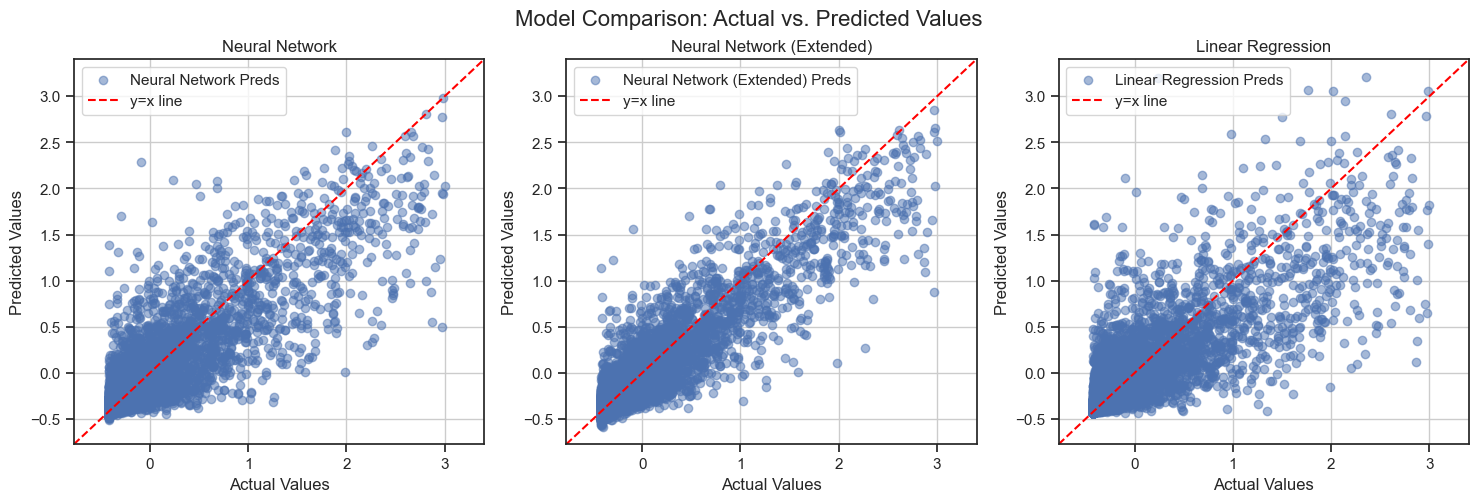

In [135]:
y_test_list = [y_train_scaled_pruned.values.ravel(), y_train_scaled_pruned_extended.values.ravel(), y_train_scaled_pruned.values.ravel()]
y_pred_list = [y_pred_neural, y_pred_neural_extended, y_pred_linear]
model_names = ["Neural Network", "Neural Network (Extended)", "Linear Regression"]


num_models = len(y_test_list)

# --- Calculate overall min/max for consistent axis limits ---
all_values = y_test_list + y_pred_list

y_flat = np.concatenate([df for df in all_values])

# 4) 전체(테스트+예측)에서의 최솟/최댓값
min_val = y_flat.min()
max_val = y_flat.max()

# Add a small padding for better visualization
padding = (max_val - min_val) * 0.05
plot_min = min_val - padding
plot_max = max_val + padding

# --- Create subplots ---
# Adjust layout based on number of models (e.g., 1 row or multiple rows)
ncols = min(num_models, 3) # Max 3 plots per row
nrows = int(np.ceil(num_models / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False) # Ensure axes is always 2D array
axes = axes.flatten() # Flatten axes array for easy iteration

fig.suptitle('Model Comparison: Actual vs. Predicted Values', fontsize=16)

# --- Generate plots for each model ---
for i in range(num_models):
    y_test_current = y_test_list[i]
    y_pred_current = y_pred_list[i]
    model_name = model_names[i]
    ax = axes[i] # Select the appropriate subplot axis
    # Scatter plot
    ax.scatter(y_test_current, y_pred_current, alpha=0.5, label=f'{model_name} Preds')

    # y=x line (Ideal prediction line)
    ax.plot([plot_min, plot_max], [plot_min, plot_max],
            color='red', linestyle='--', label='y=x line')

    # Labels and Title
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title(f"{model_name}")

    # Set consistent limits for comparison
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)

    # Legend and Grid
    ax.legend()
    ax.grid(True)


plt.show()

What stands out when looking at the graph is that the Extended version is clearly overfitting, with its points clustering much more tightly around the red dot than in the other plots.

This time, I’ll include the values of revenue ≥ 3 that were previously filtered out and see how it performs.

In [136]:
y_pred_neural = movie_revenue_mlp_regressor.predict(X_test_scaled)
y_pred_neural_extended = movie_revenue_extended_mlp_regressor.predict(X_test_scaled_extended)
y_pred_linear = movie_revenue_linear.predict(X_test_scaled.iloc[:, 0:5])

In [137]:

print(f"--- Base Model Performance ---")
r2_1 = r2_score(y_test_scaled, y_pred_neural)
rmse_1 = root_mean_squared_error(y_test_scaled, y_pred_neural)
mae_1 = mean_absolute_error(y_test_scaled, y_pred_neural)
n = X_test_scaled.shape[0]  # test set sample size
p = X_train_scaled.shape[1]  # number of features used in training
adjusted_r2_1 = 1 - (1 - r2_1) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_1:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_1:.4f}")
print(f"RMSE: {rmse_1:.4f}")
print(f"MAE: {mae_1:.4f}")


print(f"\n--- Extended Model Performance ---")
r2_2 = r2_score(y_test_scaled_extended, y_pred_neural_extended)
rmse_2 = root_mean_squared_error(y_test_scaled_extended, y_pred_neural_extended)
mae_2 = mean_absolute_error(y_test_scaled_extended, y_pred_neural_extended)
n = X_test_scaled_extended.shape[0]  # test set sample size
p = X_train_scaled_extended.shape[1]  # number of features used in training
adjusted_r2_2 = 1 - (1 - r2_2) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_2:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_2:.4f}")
print(f"RMSE: {rmse_2:.4f}")
print(f"MAE: {mae_2:.4f}")


print(f"\n--- Linear Regression Performance ---")
r2_3 = r2_score(y_test_scaled, y_pred_linear)
rmse_3 = root_mean_squared_error(y_test_scaled, y_pred_linear)
mae_3 = mean_absolute_error(y_test_scaled, y_pred_linear)
n = X_test_scaled.iloc[:,0:5].shape[0]  # test set sample size
p = X_train_scaled.iloc[:,0:5].shape[1]  # number of features used in training
adjusted_r2_3 = 1 - (1 - r2_3) * (n - 1) / (n - p - 1)

print(f"R^2 Score: {r2_3:.4f}")
print(f"Adjusted R^2 Score: {adjusted_r2_3:.4f}")
print(f"RMSE: {rmse_3:.4f}")
print(f"MAE: {mae_3:.4f}")

--- Base Model Performance ---
R^2 Score: 0.5987
Adjusted R^2 Score: 0.5810
RMSE: 0.6508
MAE: 0.2174

--- Extended Model Performance ---
R^2 Score: 0.5806
Adjusted R^2 Score: 0.4561
RMSE: 0.6654
MAE: 0.2215

--- Linear Regression Performance ---
R^2 Score: 0.5963
Adjusted R^2 Score: 0.5953
RMSE: 0.6528
MAE: 0.2310


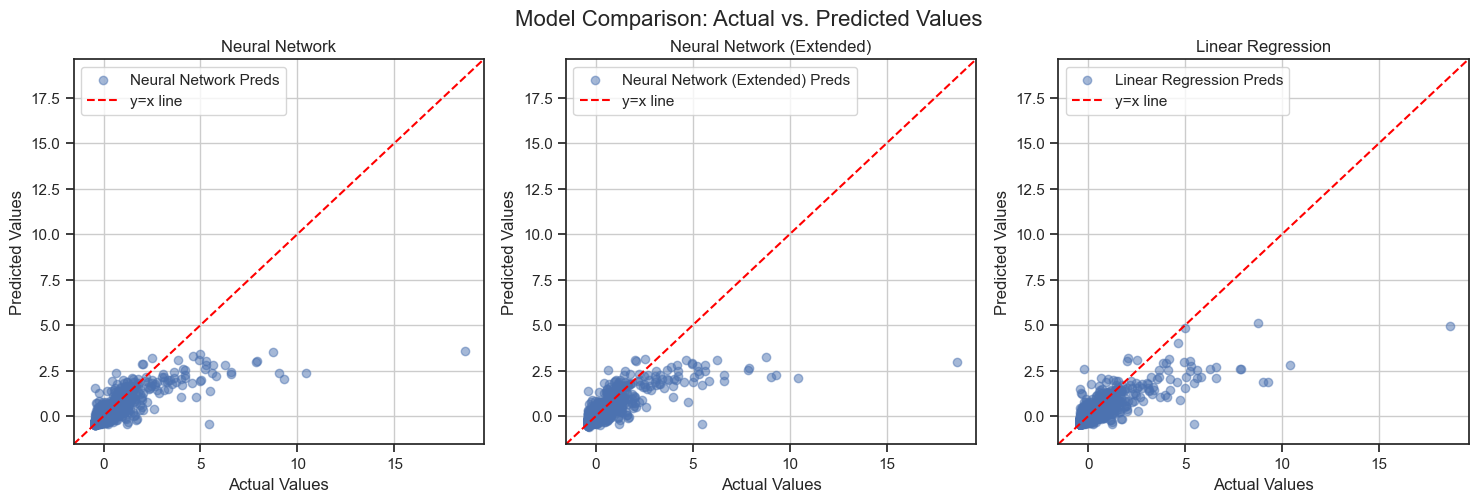

In [138]:
y_test_list = [y_test_scaled.values.ravel(), y_test_scaled_extended.values.ravel(), y_test_scaled.values.ravel()]
y_pred_list = [y_pred_neural, y_pred_neural_extended, y_pred_linear]
model_names = ["Neural Network", "Neural Network (Extended)", "Linear Regression"]


num_models = len(y_test_list)

# --- Calculate overall min/max for consistent axis limits ---
all_values = y_test_list + y_pred_list

y_flat = np.concatenate([df for df in all_values])


min_val = y_flat.min()
max_val = y_flat.max()

# Add a small padding for better visualization
padding = (max_val - min_val) * 0.05
plot_min = min_val - padding
plot_max = max_val + padding

# --- Create subplots ---
# Adjust layout based on number of models (e.g., 1 row or multiple rows)
ncols = min(num_models, 3) # Max 3 plots per row
nrows = int(np.ceil(num_models / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False) # Ensure axes is always 2D array
axes = axes.flatten() # Flatten axes array for easy iteration

fig.suptitle('Model Comparison: Actual vs. Predicted Values', fontsize=16)

# --- Generate plots for each model ---
for i in range(num_models):
    y_test_current = y_test_list[i]
    y_pred_current = y_pred_list[i]
    model_name = model_names[i]
    ax = axes[i] # Select the appropriate subplot axis
    # Scatter plot
    ax.scatter(y_test_current, y_pred_current, alpha=0.5, label=f'{model_name} Preds')

    # y=x line (Ideal prediction line)
    ax.plot([plot_min, plot_max], [plot_min, plot_max],
            color='red', linestyle='--', label='y=x line')

    # Labels and Title
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title(f"{model_name}")

    # Set consistent limits for comparison
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)

    # Legend and Grid
    ax.legend()
    ax.grid(True)


plt.show()

Looking at the scatter plot, we can see that values ≥ 3 generally follow a logarithmic pattern. In other words, it’s not that we can’t predict them at all, but we underpredict them relative to their true values, so we fail to form a linear relationship. The Linear Regression plot is more dispersed overall, but it does predict values somewhat closer to the red line (the true values). To examine this more clearly, let’s filter for values ≥ 3 and take a closer look.

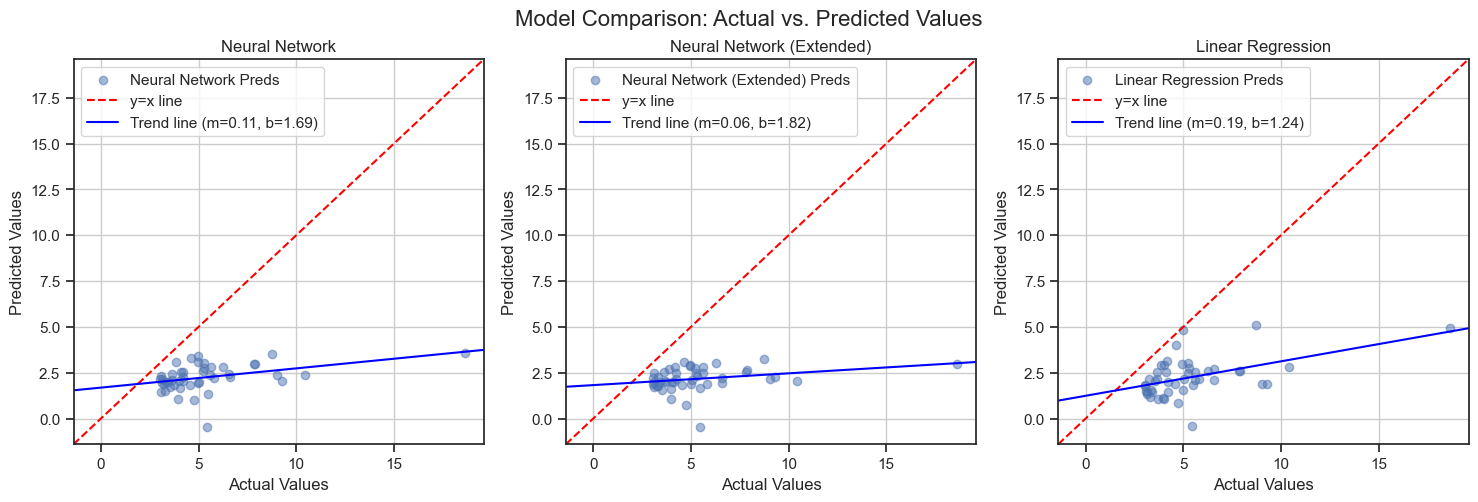

In [139]:
y_test_scaled_big = y_test_scaled[y_test_scaled["revenue"] > 3]
y_test_scaled_extended_big  = y_test_scaled_extended[y_test_scaled_extended["revenue"] > 3]

y_pred_neural = pd.DataFrame(y_pred_neural, index=y_test_scaled.index, columns=["revenue"])
y_pred_neural_extended = pd.DataFrame(y_pred_neural_extended, index=y_test_scaled_extended.index, columns=["revenue"])
y_pred_linear = pd.DataFrame(y_pred_linear, index=y_test_scaled.index, columns=["revenue"])

y_pred_neural_big = y_pred_neural.loc[y_test_scaled_big.index]
y_pred_neural_extended_big = y_pred_neural_extended.loc[y_test_scaled_extended_big.index]
y_pred_linear_big = y_pred_linear.loc[y_test_scaled_big.index]

y_test_list = [y_test_scaled_big.values.ravel(), y_test_scaled_extended_big.values.ravel(), y_test_scaled_big.values.ravel()]
y_pred_list = [y_pred_neural_big.values.ravel(), y_pred_neural_extended_big.values.ravel(), y_pred_linear_big.values.ravel()]
model_names = ["Neural Network", "Neural Network (Extended)", "Linear Regression"]


num_models = len(y_test_list)

# --- Calculate overall min/max for consistent axis limits ---
all_values = y_test_list + y_pred_list

y_flat = np.concatenate([df for df in all_values])

# 4) 전체(테스트+예측)에서의 최솟/최댓값
min_val = y_flat.min()
max_val = y_flat.max()

# Add a small padding for better visualization
padding = (max_val - min_val) * 0.05
plot_min = min_val - padding
plot_max = max_val + padding

# --- Create subplots ---
# Adjust layout based on number of models (e.g., 1 row or multiple rows)
ncols = min(num_models, 3) # Max 3 plots per row
nrows = int(np.ceil(num_models / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False) # Ensure axes is always 2D array
axes = axes.flatten() # Flatten axes array for easy iteration

fig.suptitle('Model Comparison: Actual vs. Predicted Values', fontsize=16)

# --- Generate plots for each model ---
for i in range(num_models):
    y_test_current = y_test_list[i]
    y_pred_current = y_pred_list[i]
    model_name = model_names[i]
    ax = axes[i]

    ax.scatter(y_test_current, y_pred_current, alpha=0.5, label=f'{model_names[i]} Preds')

    # --- y=x line ---
    ax.plot([plot_min, plot_max], [plot_min, plot_max],
            color='red', linestyle='--', label='y=x line')

    # --- Trend line ---
    m, b = np.polyfit(y_test_current, y_pred_current, 1)   # find slope (m) and intercept (b) of the trend line(linear regression line)
    trend_x = np.array([plot_min, plot_max])
    trend_y = m * trend_x + b
    ax.plot(trend_x, trend_y,
            color='blue', linestyle='-', label=f'Trend line (m={m:.2f}, b={b:.2f})')

    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title(model_names[i])
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)
    ax.legend()
    ax.grid(True)


plt.show()

Looking at the graph, if you draw a reference line the slopes are 0.06, 0.11, and 0.19 respectively. The Linear Regression version—which appears to be the least overfitted—displays the slope closest to the ideal. One noteworthy point is that the tendency to cluster tightly around that reference line is strongest in the order: Extended version, Base version, then Linear Regression.

## Conclusion

This project focused on predicting movie revenue using machine learning algorithms, specifically employing Neural Network (NN) and Linear Regression (LR) models.

Initial progress faced challenges due to the presence of significant noise and irrelevant data within the dataset. To address this and mitigate the risk of overfitting, a feature reduction strategy was implemented. Through iterative hyperparameter tuning, an optimal configuration was sought for the models. During this process, it was noted that training the Neural Network required considerable computational time. Ultimately, the optimized NN model successfully achieved an R² score of approximately 0.7.

An experiment involving the embedding of movie overviews, while part of the initial plan, resulted in only marginal performance improvements for revenue prediction and unfortunately intensified the overfitting problem.

Subsequently, a Linear Regression model was developed. While its overall predictive performance was lower than the Neural Network's, it exhibited a lower degree of overfitting. Notably, the LR model demonstrated greater robustness, showing the least performance degradation when evaluated on benchmark datasets that included movies with extreme revenue values.

### Future Work

Future work will prioritize enhancing the efficiency of the Neural Network approach. Utilizing GPU-accelerated frameworks, such as PyTorch, is planned to significantly reduce training times. Additionally, a potential future direction for leveraging this dataset involves exploring the use of overview embeddings specifically for the task of predicting movie genres, rather than revenue.

And next time I work in a Jupyter notebook, I’ll use functions to make the work cleaner. Looking back, if I had used functions, the document would have been much more concise and visually appealing. However, Jupyter notebooks feel different from regular coding, so I’m still not accustomed to them and using functions feels awkward.